<a href="https://colab.research.google.com/github/anishnath02/scg-classification/blob/main/SCG_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import scipy.io as sio
import scipy.signal as signal
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
from google.colab import files

uploaded = files.upload()

Saving CP-01-ECG.mat to CP-01-ECG.mat
Saving CP-01-SCG.mat to CP-01-SCG.mat
Saving CP-01-Vectors.mat to CP-01-Vectors.mat


In [3]:
import scipy.io as sio

for filename in uploaded:
    data = sio.loadmat(filename)
    print(f"\n{filename}")
    print(data.keys())


CP-01-ECG.mat
dict_keys(['__header__', '__version__', '__globals__', 'data', '__function_workspace__'])

CP-01-SCG.mat
dict_keys(['__header__', '__version__', '__globals__', 'data', '__function_workspace__'])

CP-01-Vectors.mat
dict_keys(['__header__', '__version__', '__globals__', 'Shimmer_D0CD_Accel_LN_X_CAL1', 'Shimmer_D0CD_Accel_LN_Y_CAL1', 'Shimmer_D0CD_Accel_LN_Z_CAL1', 'Shimmer_D0CD_ECG_EMG_Status1_CAL1', 'Shimmer_D0CD_ECG_EMG_Status2_CAL1', 'Shimmer_D0CD_ECG_LARA_24BIT_CAL1', 'Shimmer_D0CD_ECG_LLLA_24BIT_CAL1', 'Shimmer_D0CD_ECG_LLRA_24BIT_CAL1', 'Shimmer_D0CD_ECG_VxRL_24BIT_CAL1', 'Shimmer_D0CD_Gyro_X_CAL1', 'Shimmer_D0CD_Gyro_Y_CAL1', 'Shimmer_D0CD_Gyro_Z_CAL1', 'Shimmer_D0CD_Timestamp_Shimmer_CAL1', 'None', '__function_workspace__'])


In [4]:
import scipy.io as sio
import numpy as np

filenames = [
    "CP-01-Vectors.mat",
    "CP-01-ECG.mat",
    "CP-01-SCG.mat"
]

for filename in filenames:
    data = sio.loadmat(filename)

    print(f"\n{'='*50}")
    print("FILE:", filename)

    for key, value in data.items():
        if not key.startswith("__"):
            print(f"{key}: shape={np.shape(value)}, dtype={getattr(value, 'dtype', type(value))}")


FILE: CP-01-Vectors.mat
Shimmer_D0CD_Accel_LN_X_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Accel_LN_Y_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Accel_LN_Z_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_EMG_Status1_CAL1: shape=(124838, 1), dtype=uint8
Shimmer_D0CD_ECG_EMG_Status2_CAL1: shape=(124838, 1), dtype=uint8
Shimmer_D0CD_ECG_LARA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_LLLA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_LLRA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_VxRL_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_X_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_Y_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_Z_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Timestamp_Shimmer_CAL1: shape=(124838, 1), dtype=float64
None: shape=(1,), dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')]

FILE: CP-01-ECG.mat
data: shape=(1, 1), dtype=[('R_loc', 'O'

In [5]:
import scipy.io as sio
import numpy as np

for filename in ["CP-01-ECG.mat", "CP-01-SCG.mat"]:

    mat = sio.loadmat(filename)
    struct = mat["data"][0, 0]

    print("\n" + "="*50)
    print("FILE:", filename)

    for field in ["R_loc", "RR_int"]:

        values = struct[field]

        print(f"\n{field}")
        print("Shape:", values.shape)
        print("Data type:", values.dtype)

        for i, item in enumerate(np.ravel(values)):
            print(f"Element {i}:")
            print("  Type:", type(item))
            print("  Shape:", np.shape(item))
            print("  Value preview:", repr(item)[:300])


FILE: CP-01-ECG.mat

R_loc
Shape: (1, 3)
Data type: object
Element 0:
  Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
  Shape: (1,)
  Value preview: MatlabOpaque([(b'', b'MCOS', b'duration', array([[3707764736],
                     [         2],
                     [         1],
                     [         1],
                     [         1],
                     [         1]], dtype=uint32))            ],
             dtype=[('s0', 'O'),
Element 1:
  Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
  Shape: (1,)
  Value preview: MatlabOpaque([(b'', b'MCOS', b'duration', array([[3707764736],
                     [         2],
                     [         1],
                     [         1],
                     [         2],
                     [         1]], dtype=uint32))            ],
             dtype=[('s0', 'O'),
Element 2:
  Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
  Shape: (1,)
  Value preview: MatlabOpaque([(b'', b'MCOS', b'd

In [6]:
mat = sio.loadmat("CP-01-Vectors.mat")

timestamp = mat["Shimmer_D0CD_Timestamp_Shimmer_CAL1"].flatten()

print("First 10 timestamps:", timestamp[:10])

diff = np.diff(timestamp)

print("Median timestamp difference:", np.median(diff))
print("Estimated sampling frequency:", 1 / np.median(diff))
print("Duration (seconds):", len(timestamp) / 256)
print("Duplicate timestamps:", np.sum(diff == 0))

First 10 timestamps: [12056.73217773 12064.54467773 12068.45092773 12072.35717773
 12076.26342773 12080.16967773 12084.07592773 12087.98217773
 12091.88842773 12095.79467773]
Median timestamp difference: 3.90625
Estimated sampling frequency: 0.256
Duration (seconds): 487.6484375
Duplicate timestamps: 0


## **Next: visualize ECG and SCG signals**

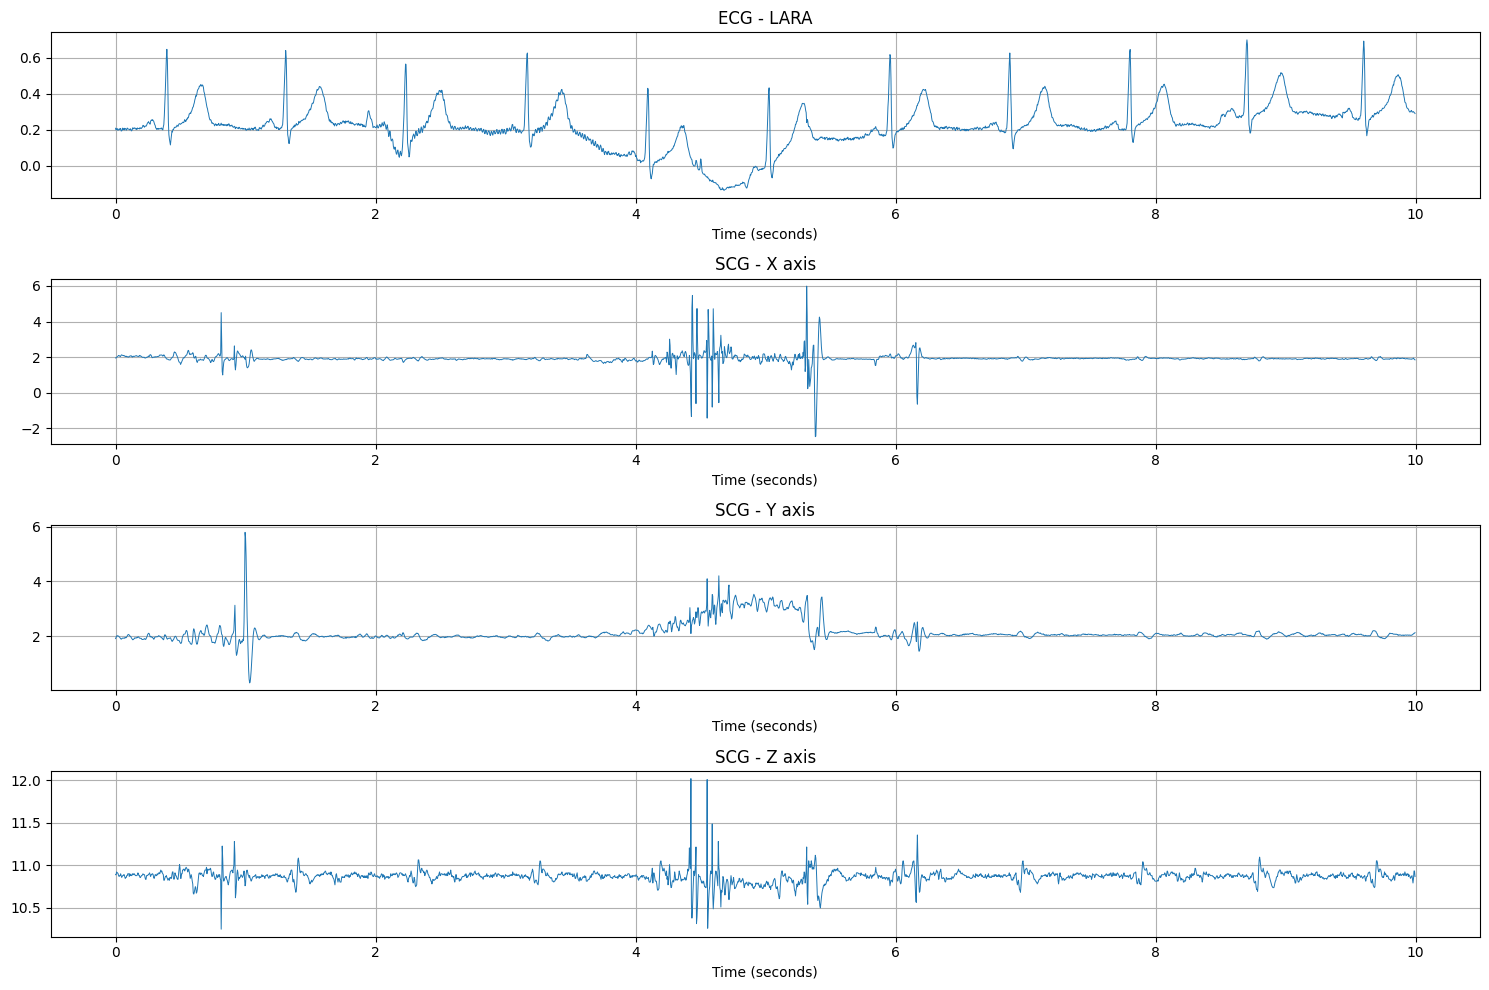

In [7]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

data = sio.loadmat("CP-01-Vectors.mat")

fs = 256
duration = 10
n = fs * duration

# ECG channel
ecg = data["Shimmer_D0CD_ECG_LARA_24BIT_CAL1"].flatten()

# SCG channels
scg_x = data["Shimmer_D0CD_Accel_LN_X_CAL1"].flatten()
scg_y = data["Shimmer_D0CD_Accel_LN_Y_CAL1"].flatten()
scg_z = data["Shimmer_D0CD_Accel_LN_Z_CAL1"].flatten()

time = np.arange(n) / fs

fig, axes = plt.subplots(4, 1, figsize=(15, 10))

signals = [
    (ecg, "ECG - LARA"),
    (scg_x, "SCG - X axis"),
    (scg_y, "SCG - Y axis"),
    (scg_z, "SCG - Z axis")
]

for ax, (sig, title) in zip(axes, signals):
    ax.plot(time, sig[:n], linewidth=0.7)
    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.grid(True)

plt.tight_layout()
plt.show()

## **RR intervals**

In [8]:
for filename in ["CP-01-ECG.mat", "CP-01-SCG.mat"]:
    mat = sio.loadmat(filename)
    rr = mat["data"][0, 0]["RR_int"]

    print("\n", filename)

    for i, channel in enumerate(rr.flatten()):
        values = np.asarray(channel).flatten()

        print(
            f"Channel {i+1}: "
            f"Count={len(values)}, "
            f"Mean={np.mean(values):.2f} ms, "
            f"Min={np.min(values):.2f} ms, "
            f"Max={np.max(values):.2f} ms"
        )


 CP-01-ECG.mat
Channel 1: Count=522, Mean=882.37 ms, Min=707.03 ms, Max=933.59 ms
Channel 2: Count=522, Mean=882.38 ms, Min=707.03 ms, Max=933.59 ms
Channel 3: Count=522, Mean=882.38 ms, Min=707.03 ms, Max=937.50 ms

 CP-01-SCG.mat
Channel 1: Count=521, Mean=882.30 ms, Min=679.69 ms, Max=1097.66 ms
Channel 2: Count=521, Mean=882.29 ms, Min=574.22 ms, Max=1207.03 ms
Channel 3: Count=521, Mean=882.31 ms, Min=699.22 ms, Max=1000.00 ms


## **preprocessing**

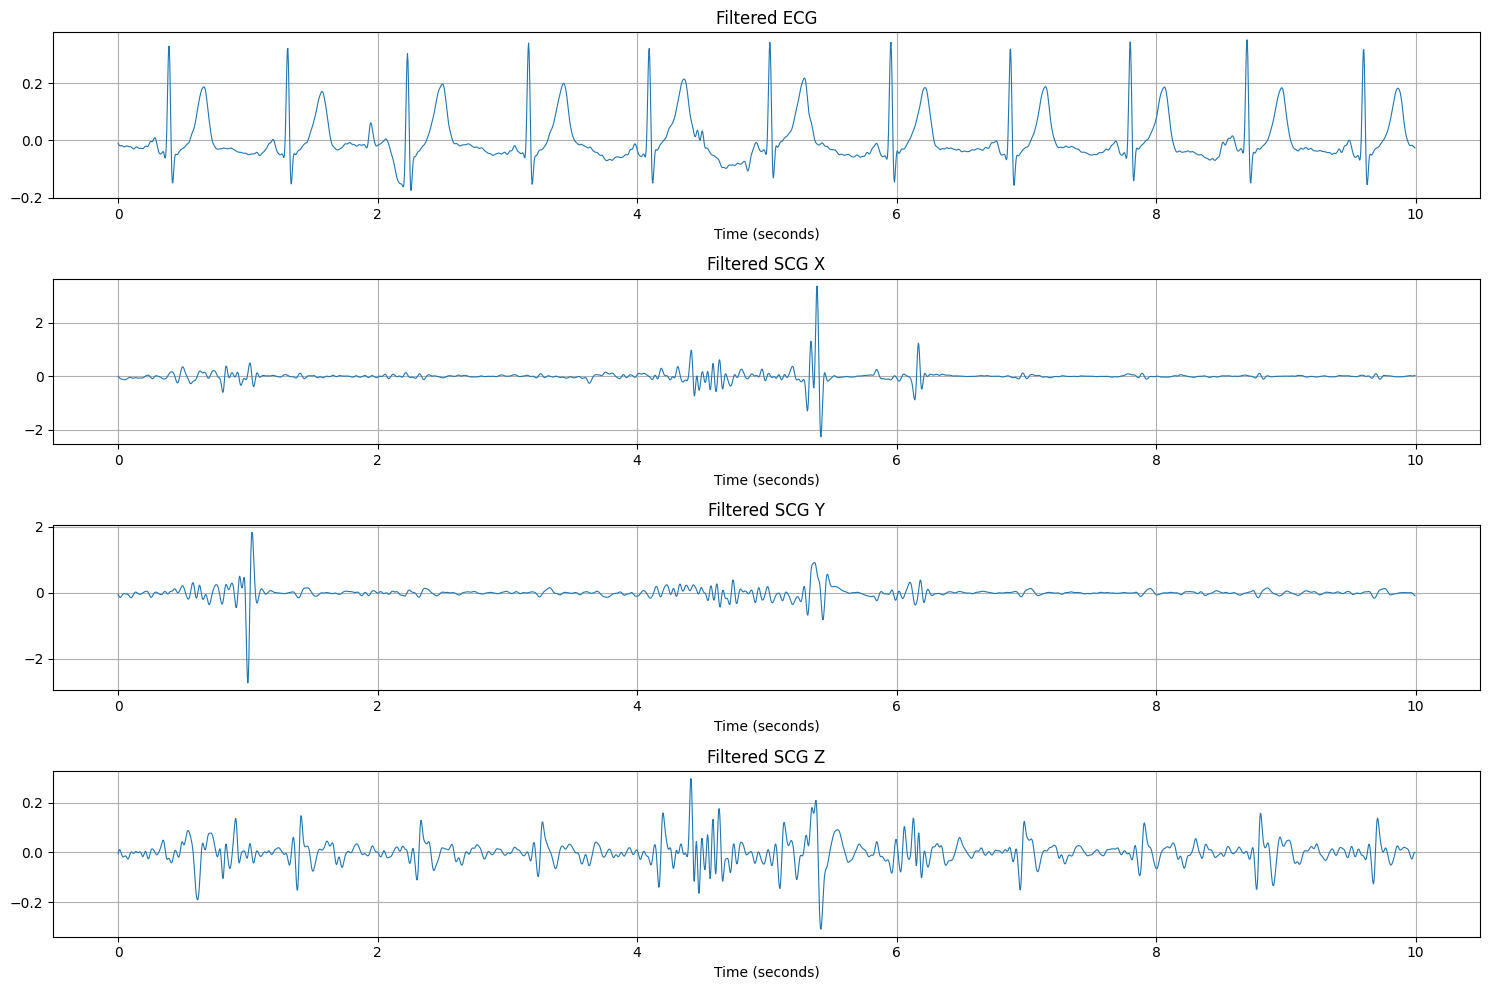

In [9]:
from scipy.signal import butter, sosfiltfilt
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio

data = sio.loadmat("CP-01-Vectors.mat")

fs = 256

# Load ECG
ecg = data["Shimmer_D0CD_ECG_LARA_24BIT_CAL1"].flatten()

# Load and correct SCG axes
scg_x = -data["Shimmer_D0CD_Accel_LN_X_CAL1"].flatten()
scg_y = -data["Shimmer_D0CD_Accel_LN_Y_CAL1"].flatten()
scg_z = data["Shimmer_D0CD_Accel_LN_Z_CAL1"].flatten()

# Butterworth bandpass filtering
def bandpass_filter(signal_data, low, high, fs, order=4):
    sos = butter(
        order,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, signal_data)

# Filter signals
ecg_filtered = bandpass_filter(ecg, 0.8, 30, fs)

scg_x_filtered = bandpass_filter(scg_x, 0.8, 25, fs)
scg_y_filtered = bandpass_filter(scg_y, 0.8, 25, fs)
scg_z_filtered = bandpass_filter(scg_z, 0.8, 25, fs)

# Plot first 10 seconds
n = 10 * fs
t = np.arange(n) / fs

signals = [
    (ecg_filtered, "Filtered ECG"),
    (scg_x_filtered, "Filtered SCG X"),
    (scg_y_filtered, "Filtered SCG Y"),
    (scg_z_filtered, "Filtered SCG Z")
]

fig, axes = plt.subplots(4, 1, figsize=(15, 10))

for ax, (sig, title) in zip(axes, signals):
    ax.plot(t, sig[:n], linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.grid(True)

plt.tight_layout()
plt.show()

## **ECG R-peak detection**

Detected R-peaks: 552
Mean RR: 883.0535390199638 ms
Mean heart rate: 67.9460500963391 BPM


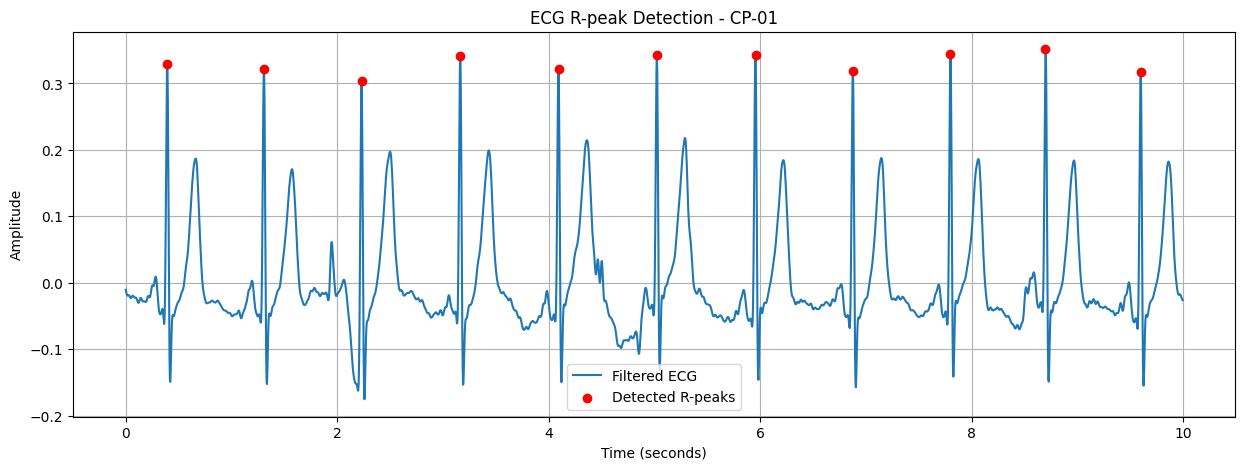

In [10]:
from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

# Detect R-peaks
peaks, properties = find_peaks(
    ecg_filtered,
    distance=int(0.45 * fs),
    prominence=0.08
)

# Calculate RR intervals
rr_detected = np.diff(peaks) / fs * 1000

print("Detected R-peaks:", len(peaks))
print("Mean RR:", np.mean(rr_detected), "ms")
print("Mean heart rate:", 60000 / np.mean(rr_detected), "BPM")

# Plot first 10 seconds
n = 10 * fs
t = np.arange(n) / fs

plt.figure(figsize=(15, 5))
plt.plot(t, ecg_filtered[:n], label="Filtered ECG")
visible_peaks = peaks[peaks < n]

plt.scatter(
    visible_peaks / fs,
    ecg_filtered[visible_peaks],
    color="red",
    label="Detected R-peaks",
    zorder=3
)

plt.title("ECG R-peak Detection - CP-01")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

DETECTED RR
Count: 551
Mean: 883.0535390199638
Median: 882.8125
Min: 707.03125
Max: 1031.25

REFERENCE RR
Count: 522
Mean: 882.3709889846743
Median: 882.8125
Min: 707.03125
Max: 933.59375


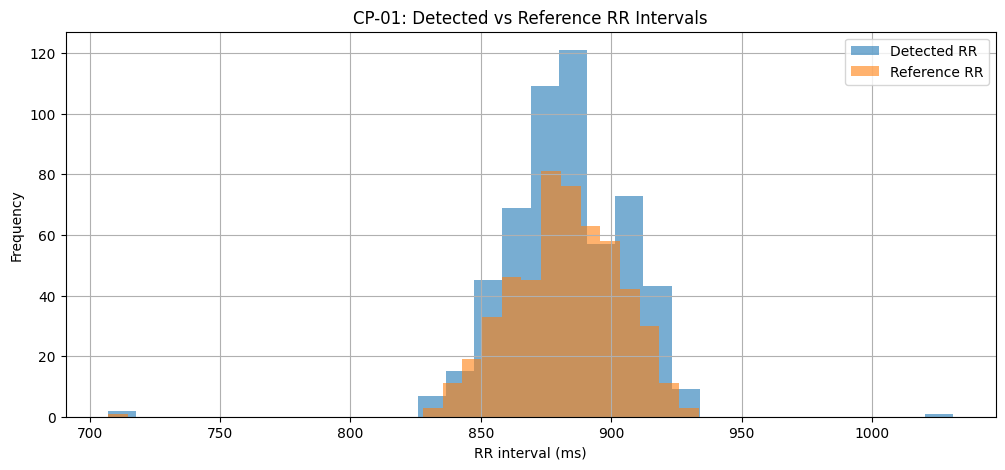

In [11]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt

# Detected RR intervals
detected_rr = np.diff(peaks) / fs * 1000

# Supplied ECG RR intervals
mat = sio.loadmat("CP-01-ECG.mat")
rr_data = mat["data"][0, 0]["RR_int"]

reference_rr = np.asarray(rr_data[0, 0]).flatten()

print("DETECTED RR")
print("Count:", len(detected_rr))
print("Mean:", np.mean(detected_rr))
print("Median:", np.median(detected_rr))
print("Min:", np.min(detected_rr))
print("Max:", np.max(detected_rr))

print("\nREFERENCE RR")
print("Count:", len(reference_rr))
print("Mean:", np.mean(reference_rr))
print("Median:", np.median(reference_rr))
print("Min:", np.min(reference_rr))
print("Max:", np.max(reference_rr))

# Compare distributions
plt.figure(figsize=(12, 5))

plt.hist(detected_rr, bins=30, alpha=0.6, label="Detected RR")
plt.hist(reference_rr, bins=30, alpha=0.6, label="Reference RR")

plt.xlabel("RR interval (ms)")
plt.ylabel("Frequency")
plt.title("CP-01: Detected vs Reference RR Intervals")
plt.legend()
plt.grid(True)
plt.show()

## **investigate the discrepancy**

In [12]:
import numpy as np
import scipy.io as sio

# Load reference RR intervals
mat = sio.loadmat("CP-01-ECG.mat")
rr_data = mat["data"][0, 0]["RR_int"]

reference_rr = np.asarray(rr_data[0, 0]).flatten()

# Detected RR intervals
detected_rr = np.diff(peaks) / fs * 1000

# Cumulative elapsed time
detected_time = np.cumsum(detected_rr) / 1000
reference_time = np.cumsum(reference_rr) / 1000

print("Detected sequence duration:", detected_time[-1], "seconds")
print("Reference sequence duration:", reference_time[-1], "seconds")

print("\nFirst 20 detected RR:")
print(np.round(detected_rr[:20], 2))

print("\nFirst 20 reference RR:")
print(np.round(reference_rr[:20], 2))

print("\nLast 10 detected RR:")
print(np.round(detected_rr[-10:], 2))

print("\nLast 10 reference RR:")
print(np.round(reference_rr[-10:], 2))

Detected sequence duration: 486.5625 seconds
Reference sequence duration: 460.59765625 seconds

First 20 detected RR:
[917.97 921.88 933.59 929.69 929.69 933.59 921.88 921.88 898.44 902.34
 890.62 894.53 886.72 890.62 878.91 890.62 894.53 882.81 882.81 890.62]

First 20 reference RR:
[890.62 894.53 886.72 890.62 878.91 890.62 894.53 882.81 882.81 890.62
 867.19 882.81 871.09 859.38 875.   882.81 871.09 875.   875.   843.75]

Last 10 detected RR:
[882.81 875.   867.19 882.81 875.   867.19 886.72 894.53 898.44 894.53]

Last 10 reference RR:
[921.88 917.97 906.25 914.06 906.25 914.06 917.97 902.34 921.88 914.06]


## **whether the sequences are offset**

Best detected sequence offset: 10
Best alignment MAE: 0.015 ms
Reference mean: 882.371 ms
Aligned detected mean: 882.371 ms


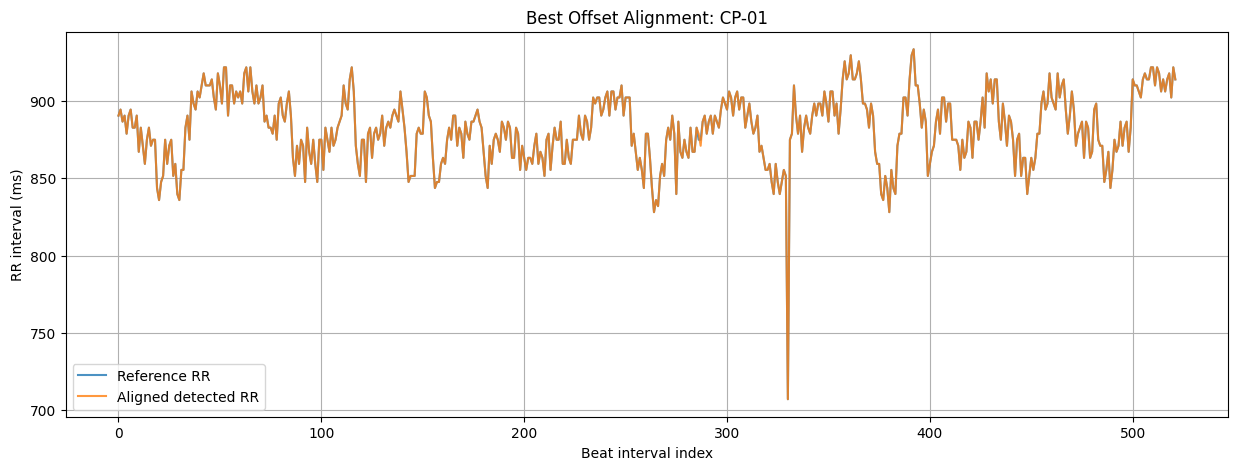

In [13]:
import numpy as np
import matplotlib.pyplot as plt

det = detected_rr
ref = reference_rr

# Find the best fixed offset
results = []

for offset in range(len(det) - len(ref) + 1):
    segment = det[offset:offset + len(ref)]
    mae = np.mean(np.abs(segment - ref))
    results.append((mae, offset))

best_mae, best_offset = min(results)

aligned_det = det[best_offset:best_offset + len(ref)]

print("Best detected sequence offset:", best_offset)
print("Best alignment MAE:", round(best_mae, 3), "ms")
print("Reference mean:", round(np.mean(ref), 3), "ms")
print("Aligned detected mean:", round(np.mean(aligned_det), 3), "ms")

plt.figure(figsize=(15, 5))
plt.plot(ref, label="Reference RR", alpha=0.8)
plt.plot(aligned_det, label="Aligned detected RR", alpha=0.8)
plt.xlabel("Beat interval index")
plt.ylabel("RR interval (ms)")
plt.title("Best Offset Alignment: CP-01")
plt.legend()
plt.grid()
plt.show()

## **inspect all three reference channels**

In [14]:
import scipy.io as sio
import numpy as np

for filename in ["CP-01-ECG.mat", "CP-01-SCG.mat"]:

    mat = sio.loadmat(filename)
    rr = mat["data"][0, 0]["RR_int"]

    print("\n", filename)

    for i in range(3):
        reference = np.asarray(rr[0, i]).flatten()

        print(
            f"Channel {i+1}: "
            f"Count={len(reference)}, "
            f"Mean={np.mean(reference):.3f} ms"
        )


 CP-01-ECG.mat
Channel 1: Count=522, Mean=882.371 ms
Channel 2: Count=522, Mean=882.378 ms
Channel 3: Count=522, Mean=882.378 ms

 CP-01-SCG.mat
Channel 1: Count=521, Mean=882.295 ms
Channel 2: Count=521, Mean=882.288 ms
Channel 3: Count=521, Mean=882.310 ms


## **SCG cardiac-cycle segmentation**

In [15]:
# Use detected ECG R-peaks to segment all SCG axes

scg_signals = {
    "X": scg_x_filtered,
    "Y": scg_y_filtered,
    "Z": scg_z_filtered
}

# Window around each ECG R-peak
pre_ms = 250
post_ms = 650

pre = int(pre_ms * fs / 1000)
post = int(post_ms * fs / 1000)

scg_cycles = {axis: [] for axis in scg_signals}

for peak in peaks:
    start = peak - pre
    end = peak + post

    if start >= 0 and end <= len(ecg_filtered):
        for axis, sig in scg_signals.items():
            scg_cycles[axis].append(sig[start:end])

for axis in scg_cycles:
    scg_cycles[axis] = np.array(scg_cycles[axis])

    print(
        f"SCG {axis}:",
        scg_cycles[axis].shape
    )

SCG X: (552, 230)
SCG Y: (552, 230)
SCG Z: (552, 230)


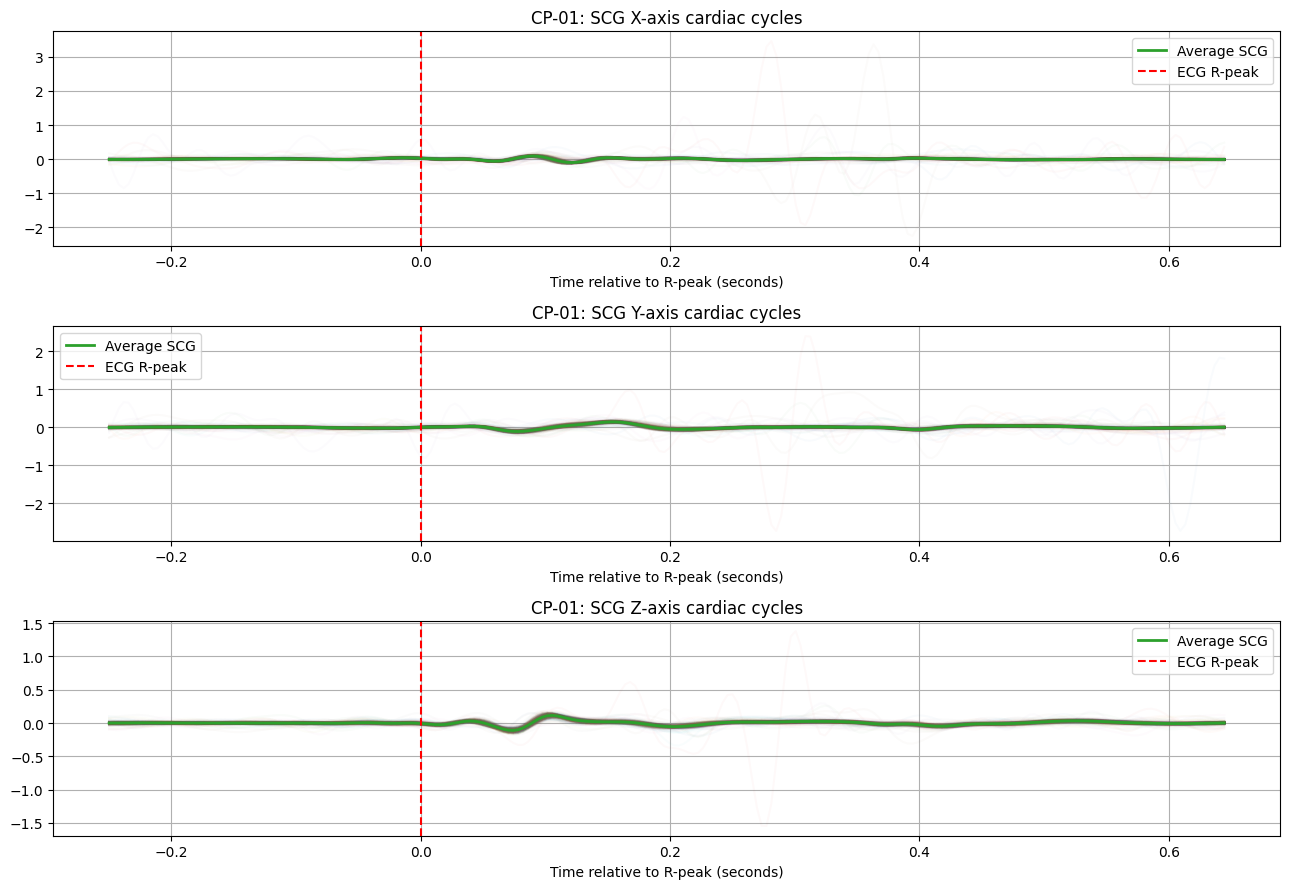

In [16]:
cycle_time = np.arange(-pre, post) / fs

fig, axes = plt.subplots(3, 1, figsize=(13, 9))

for ax, axis in zip(axes, ["X", "Y", "Z"]):

    cycles = scg_cycles[axis]

    ax.plot(cycle_time, cycles.T, alpha=0.025)
    ax.plot(
        cycle_time,
        np.mean(cycles, axis=0),
        linewidth=2,
        label="Average SCG"
    )

    ax.axvline(0, color="red", linestyle="--", label="ECG R-peak")
    ax.set_title(f"CP-01: SCG {axis}-axis cardiac cycles")
    ax.set_xlabel("Time relative to R-peak (seconds)")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## **Mean vs Median SCG morphology**

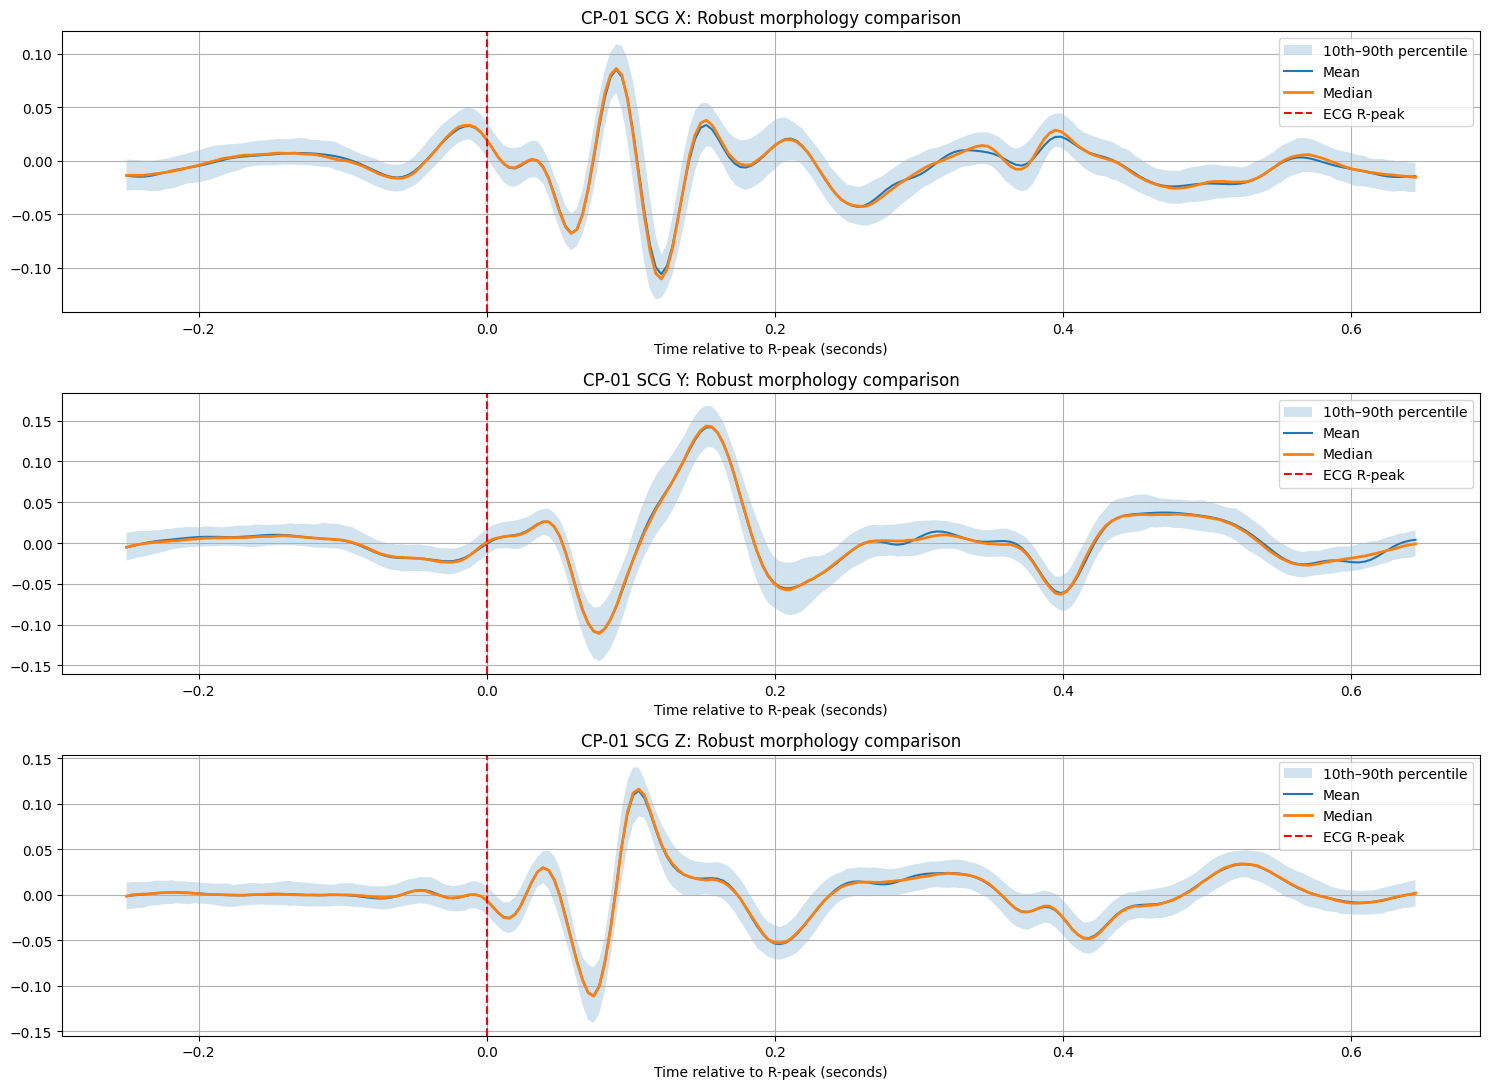

In [17]:
import numpy as np
import matplotlib.pyplot as plt

axes_names = ["X", "Y", "Z"]
cycle_time = np.arange(-pre, post) / fs

fig, plots = plt.subplots(3, 1, figsize=(15, 11))

for ax, name in zip(plots, axes_names):

    cycles = scg_cycles[name]

    # Remove each cycle's pre-R baseline offset
    baseline = np.median(cycles[:, :pre], axis=1, keepdims=True)
    corrected = cycles - baseline

    mean_wave = np.mean(corrected, axis=0)
    median_wave = np.median(corrected, axis=0)

    lower = np.percentile(corrected, 10, axis=0)
    upper = np.percentile(corrected, 90, axis=0)

    ax.fill_between(
        cycle_time, lower, upper,
        alpha=0.2, label="10th–90th percentile"
    )

    ax.plot(cycle_time, mean_wave, label="Mean", linewidth=1.5)
    ax.plot(cycle_time, median_wave, label="Median", linewidth=2)

    ax.axvline(0, color="red", linestyle="--", label="ECG R-peak")
    ax.set_title(f"CP-01 SCG {name}: Robust morphology comparison")
    ax.set_xlabel("Time relative to R-peak (seconds)")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## **Measure cycle variability and potential artifacts**

In [18]:
for name in ["X", "Y", "Z"]:

    cycles = scg_cycles[name]

    peak_to_peak = np.ptp(cycles, axis=1)

    median_amp = np.median(peak_to_peak)
    mad = np.median(np.abs(peak_to_peak - median_amp))

    threshold = median_amp + 6 * 1.4826 * mad
    flagged = peak_to_peak > threshold

    print(f"\nSCG {name}")
    print("Median cycle amplitude:", median_amp)
    print("Maximum cycle amplitude:", np.max(peak_to_peak))
    print("Potential artifact cycles:", np.sum(flagged))
    print("Potential artifact percentage:",
          round(np.mean(flagged) * 100, 2), "%")


SCG X
Median cycle amplitude: 0.2065417626854909
Maximum cycle amplitude: 5.627276792299519
Potential artifact cycles: 23
Potential artifact percentage: 4.17 %

SCG Y
Median cycle amplitude: 0.2618659385223856
Maximum cycle amplitude: 5.140969357338459
Potential artifact cycles: 14
Potential artifact percentage: 2.54 %

SCG Z
Median cycle amplitude: 0.23417791551982461
Maximum cycle amplitude: 2.9249583963039916
Potential artifact cycles: 3
Potential artifact percentage: 0.54 %


In [20]:
import scipy.io as sio
import numpy as np

mat = sio.loadmat(
    "CP-01-ECG.mat",
    struct_as_record=False,
    squeeze_me=True
)

data = mat["data"]

r_loc = data.R_loc

print("R_loc type:", type(r_loc))
print("Number of channels:", len(r_loc))

for i, channel in enumerate(r_loc):
    print(f"\nChannel {i+1}:")
    print("Type:", type(channel))
    print("Content:", repr(channel)[:500])

R_loc type: <class 'numpy.ndarray'>
Number of channels: 3

Channel 1:
Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
Content: MatlabOpaque([(b'', b'MCOS', b'duration', array([3707764736,          2,          1,          1,          1,
                              1], dtype=uint32))                                                            ],
             dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')])

Channel 2:
Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
Content: MatlabOpaque([(b'', b'MCOS', b'duration', array([3707764736,          2,          1,          1,          2,
                              1], dtype=uint32))                                                            ],
             dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')])

Channel 3:
Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
Content: MatlabOpaque([(b'', b'MCOS', b'duration', array([3707764736,          2,          1,          1,          3,
        

## **Actual ECG reference R-peak timestamps**

In [21]:
from google.colab import files

uploaded = files.upload()

Saving CP01_ECG_reference.csv to CP01_ECG_reference.csv


In [22]:
import pandas as pd

reference = pd.read_csv("CP01_ECG_reference.csv")

print(reference.shape)
print(reference.head())
print(reference.isna().sum())

(523, 3)
    Channel1   Channel2   Channel3
0   9.605469   9.605469   9.605469
1  10.496094  10.500000  10.500000
2  11.390625  11.394531  11.394531
3  12.277344  12.281250  12.281250
4  13.167969  13.171875  13.171875
Channel1    0
Channel2    0
Channel3    0
dtype: int64


In [24]:
print("fs exists:", "fs" in globals())
print("peaks exists:", "peaks" in globals())

if "fs" in globals():
    print("Sampling frequency:", fs)

if "peaks" in globals():
    print("Detected R-peaks:", len(peaks))

fs exists: True
peaks exists: True
Sampling frequency: 256
Detected R-peaks: 552


In [25]:
import numpy as np
import pandas as pd

# Detected R-peak timestamps in seconds
detected_times = peaks / fs

# Reference R-peak timestamps
reference_times = reference["Channel1"].to_numpy()

print("DETECTED R-PEAKS")
print("Count:", len(detected_times))
print("First 10:", detected_times[:10])
print("Last 5:", detected_times[-5:])
print("Time range:", detected_times[0], "to", detected_times[-1])

print("\nREFERENCE R-PEAKS")
print("Count:", len(reference_times))
print("First 10:", reference_times[:10])
print("Last 5:", reference_times[-5:])
print("Time range:", reference_times[0], "to", reference_times[-1])

DETECTED R-PEAKS
Count: 552
First 10: [0.390625   1.30859375 2.23046875 3.1640625  4.09375    5.0234375
 5.95703125 6.87890625 7.80078125 8.69921875]
Last 5: [483.37890625 484.265625   485.16015625 486.05859375 486.953125  ]
Time range: 0.390625 to 486.953125

REFERENCE R-PEAKS
Count: 523
First 10: [ 9.60546875 10.49609375 11.390625   12.27734375 13.16796875 14.046875
 14.9375     15.83203125 16.71484375 17.59765625]
Last 5: [466.546875   467.46484375 468.3671875  469.2890625  470.203125  ]
Time range: 9.60546875 to 470.203125


In [26]:

import numpy as np

# 1. Convert both sets of peaks into seconds
detected_times = np.sort(np.asarray(peaks) / fs)
reference_times = np.sort(reference["Channel1"].to_numpy())

# 2. Set matching tolerance
tolerance = 0.050  # 50 milliseconds

# 3. One-to-one chronological matching
i, j = 0, 0
matched_errors = []

while i < len(detected_times) and j < len(reference_times):

    difference = detected_times[i] - reference_times[j]

    if abs(difference) <= tolerance:
        matched_errors.append(difference)
        i += 1
        j += 1

    elif detected_times[i] < reference_times[j] - tolerance:
        i += 1

    else:
        j += 1

# 4. Calculate evaluation metrics
TP = len(matched_errors)
FP = len(detected_times) - TP
FN = len(reference_times) - TP

precision = TP / (TP + FP) if TP + FP else 0
sensitivity = TP / (TP + FN) if TP + FN else 0

f1 = (
    2 * precision * sensitivity / (precision + sensitivity)
    if precision + sensitivity else 0
)

timing_mae = (
    np.mean(np.abs(matched_errors)) * 1000
    if TP else np.nan
)

# 5. Display results
print("===== CP-01 ECG R-PEAK VALIDATION =====")
print("Matching tolerance:", tolerance * 1000, "ms")
print("Detected peaks:", len(detected_times))
print("Reference peaks:", len(reference_times))
print("--------------------------------------")
print("True Positives:", TP)
print("False Positives:", FP)
print("False Negatives:", FN)
print("--------------------------------------")
print("Precision:", round(precision * 100, 2), "%")
print("Sensitivity:", round(sensitivity * 100, 2), "%")
print("F1-score:", round(f1 * 100, 2), "%")
print("Timing MAE:", round(timing_mae, 3), "ms")


===== CP-01 ECG R-PEAK VALIDATION =====
Matching tolerance: 50.0 ms
Detected peaks: 552
Reference peaks: 523
--------------------------------------
True Positives: 523
False Positives: 29
False Negatives: 0
--------------------------------------
Precision: 94.75 %
Sensitivity: 100.0 %
F1-score: 97.3 %
Timing MAE: 3.899 ms


## **Recalculate within the reference coverage**

In [27]:

import numpy as np

det = np.sort(np.asarray(peaks) / fs)
ref = np.sort(reference["Channel1"].to_numpy())

# Evaluate only the period covered by reference annotations
det = det[(det >= ref[0]) & (det <= ref[-1])]

tolerance = 0.050
i, j = 0, 0
errors = []

while i < len(det) and j < len(ref):
    diff = det[i] - ref[j]

    if abs(diff) <= tolerance:
        errors.append(diff)
        i += 1
        j += 1
    elif det[i] < ref[j] - tolerance:
        i += 1
    else:
        j += 1

TP = len(errors)
FP = len(det) - TP
FN = len(ref) - TP

precision = TP / (TP + FP) if TP + FP else 0
sensitivity = TP / (TP + FN) if TP + FN else 0
f1 = 2 * precision * sensitivity / (precision + sensitivity) if precision + sensitivity else 0

mae = np.mean(np.abs(errors)) * 1000 if TP else np.nan

print("===== CP-01 CORRECTED ECG VALIDATION =====")
print("Reference coverage:", round(ref[0], 3), "to", round(ref[-1], 3), "seconds")
print("Detected peaks within coverage:", len(det))
print("Reference peaks:", len(ref))
print("TP:", TP, "| FP:", FP, "| FN:", FN)
print("Precision:", round(precision * 100, 2), "%")
print("Sensitivity:", round(sensitivity * 100, 2), "%")
print("F1-score:", round(f1 * 100, 2), "%")
print("Timing MAE:", round(mae, 3), "ms")


===== CP-01 CORRECTED ECG VALIDATION =====
Reference coverage: 9.605 to 470.203 seconds
Detected peaks within coverage: 522
Reference peaks: 523
TP: 522 | FP: 0 | FN: 1
Precision: 100.0 %
Sensitivity: 99.81 %
F1-score: 99.9 %
Timing MAE: 3.899 ms


## **Missed R-peaks**

In [28]:

import numpy as np

det = np.sort(np.asarray(peaks) / fs)
ref = np.sort(reference["Channel1"].to_numpy())

# Restrict detections to reference coverage
det = det[(det >= ref[0]) & (det <= ref[-1])]

tolerance = 0.050
i, j = 0, 0
errors = []
unmatched_reference = []

while i < len(det) and j < len(ref):
    diff = det[i] - ref[j]

    if abs(diff) <= tolerance:
        errors.append(diff)
        i += 1
        j += 1
    elif det[i] < ref[j] - tolerance:
        i += 1
    else:
        unmatched_reference.append(ref[j])
        j += 1

# Include any remaining reference events
unmatched_reference.extend(ref[j:])

print("Missed reference timestamps (seconds):")
print(unmatched_reference)

print("\nTiming diagnostics:")
print("Mean signed error:", round(np.mean(errors) * 1000, 3), "ms")
print("Maximum absolute error:", round(np.max(np.abs(errors)) * 1000, 3), "ms")
print("Matched beats:", len(errors))


Missed reference timestamps (seconds):
[np.float64(9.60546875)]

Timing diagnostics:
Mean signed error: -3.899 ms
Maximum absolute error: 3.906 ms
Matched beats: 522


## **Missed Heartbeat**

Reference time: 9.60546875
Nearby detected peaks: []


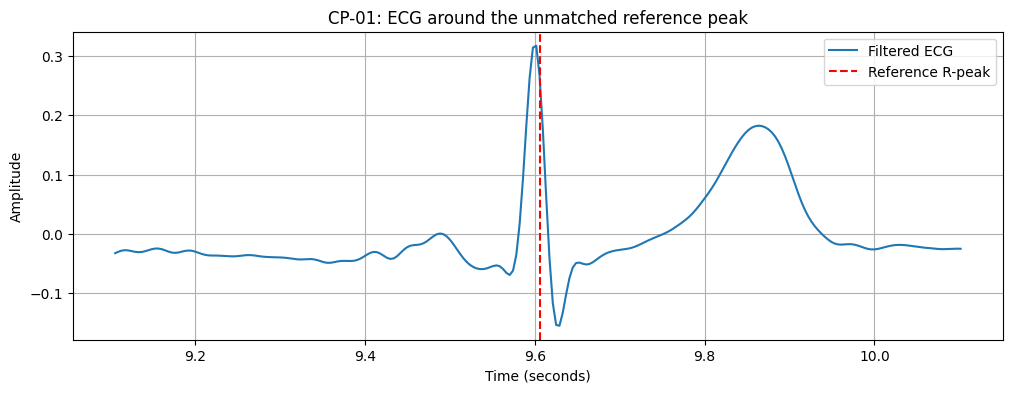

In [29]:

import numpy as np
import matplotlib.pyplot as plt

missed_time = 9.60546875

# Find detected peaks near the missed reference
nearby = det[np.abs(det - missed_time) <= 0.2]

print("Reference time:", missed_time)
print("Nearby detected peaks:", nearby)

# Plot ECG around the reference event
start = int((missed_time - 0.5) * fs)
end = int((missed_time + 0.5) * fs)

time_axis = np.arange(start, end) / fs

plt.figure(figsize=(12, 4))
plt.plot(time_axis, ecg_filtered[start:end], label="Filtered ECG")
plt.axvline(missed_time, color="red", linestyle="--",
            label="Reference R-peak")

for p in nearby:
    plt.axvline(p, color="green", linestyle=":",
                label="Detected R-peak")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("CP-01: ECG around the unmatched reference peak")
plt.legend()
plt.grid()
plt.show()


In [30]:

import numpy as np
from scipy.signal import find_peaks

reference_time = 9.60546875

# Check the original detected peak timestamps
detected_times = np.asarray(peaks) / fs

nearby = detected_times[
    np.abs(detected_times - reference_time) <= 0.2
]

print("Detected peaks within ±200 ms:", nearby)

# Find the strongest positive peak in the local ECG window
start = int((reference_time - 0.2) * fs)
end = int((reference_time + 0.2) * fs)

local_signal = ecg_filtered[start:end]
local_peaks, properties = find_peaks(local_signal)

if len(local_peaks):
    strongest = local_peaks[np.argmax(local_signal[local_peaks])]
    strongest_time = (start + strongest) / fs

    print("Strongest local peak:", strongest_time, "seconds")
    print("Difference from reference:",
          round((strongest_time - reference_time) * 1000, 3), "ms")
else:
    print("No local peaks found.")


Detected peaks within ±200 ms: [9.6015625]
Strongest local peak: 9.6015625 seconds
Difference from reference: -3.906 ms


# **Step-1 : Finalize ECG reference R-peaks**

In [31]:

import numpy as np

det = np.sort(np.asarray(peaks) / fs)
ref = np.sort(reference["Channel1"].to_numpy())

tolerance = 0.050

# Keep detections within the reference interval plus tolerance
det_eval = det[
    (det >= ref[0] - tolerance) &
    (det <= ref[-1] + tolerance)
]

i, j = 0, 0
errors = []

while i < len(det_eval) and j < len(ref):
    diff = det_eval[i] - ref[j]

    if abs(diff) <= tolerance:
        errors.append(diff)
        i += 1
        j += 1
    elif det_eval[i] < ref[j] - tolerance:
        i += 1
    else:
        j += 1

TP = len(errors)
FP = len(det_eval) - TP
FN = len(ref) - TP

precision = TP / (TP + FP) if TP + FP else 0
sensitivity = TP / (TP + FN) if TP + FN else 0
f1 = 2 * precision * sensitivity / (precision + sensitivity) if precision + sensitivity else 0

print("===== FINAL CP-01 ECG VALIDATION =====")
print("Reference events:", len(ref))
print("Detected events in evaluation interval:", len(det_eval))
print("TP:", TP, "FP:", FP, "FN:", FN)
print("Precision:", round(precision * 100, 2), "%")
print("Sensitivity:", round(sensitivity * 100, 2), "%")
print("F1-score:", round(f1 * 100, 2), "%")
print("Timing MAE:", round(np.mean(np.abs(errors)) * 1000, 3), "ms")

# Save reference R-peak times for SCG segmentation
r_times = ref.copy()


===== FINAL CP-01 ECG VALIDATION =====
Reference events: 523
Detected events in evaluation interval: 523
TP: 523 FP: 0 FN: 0
Precision: 100.0 %
Sensitivity: 100.0 %
F1-score: 100.0 %
Timing MAE: 3.899 ms


# **Step-2 : dividing SCG X, Y and Z into cardiac cycles**

In [32]:

# Find SCG-related variables currently available in Colab
for name, value in globals().copy().items():
    if "scg" in name.lower():
        if isinstance(value, np.ndarray):
            print(f"{name}: shape={value.shape}, dtype={value.dtype}")


scg_x: shape=(124838,), dtype=float64
scg_y: shape=(124838,), dtype=float64
scg_z: shape=(124838,), dtype=float64
scg_x_filtered: shape=(124838,), dtype=float64
scg_y_filtered: shape=(124838,), dtype=float64
scg_z_filtered: shape=(124838,), dtype=float64


In [33]:

import numpy as np

# Sampling frequency
fs = 256

# Filtered SCG signals
scg_signals = {
    "X": scg_x_filtered,
    "Y": scg_y_filtered,
    "Z": scg_z_filtered
}

# Convert ECG reference timestamps into sample indices
r_samples = np.round(r_times * fs).astype(int)

# Create cardiac cycles
scg_cycles = {"X": [], "Y": [], "Z": []}
cycle_times = []

for i in range(len(r_samples) - 1):

    start = r_samples[i]
    end = r_samples[i + 1]

    # Check valid sample boundaries
    if start < 0 or end > len(scg_x_filtered):
        continue

    for axis in ["X", "Y", "Z"]:
        cycle = scg_signals[axis][start:end]
        scg_cycles[axis].append(cycle)

    cycle_times.append((r_times[i], r_times[i + 1]))

# Convert lists to arrays if cycle lengths are equal
print("===== SCG SEGMENTATION RESULTS =====")

for axis in ["X", "Y", "Z"]:
    print(f"SCG {axis}: {len(scg_cycles[axis])} cycles")

print("Total possible cycles:", len(r_times) - 1)
print("First cycle duration:",
      round(cycle_times[0][1] - cycle_times[0][0], 4), "seconds")


===== SCG SEGMENTATION RESULTS =====
SCG X: 522 cycles
SCG Y: 522 cycles
SCG Z: 522 cycles
Total possible cycles: 522
First cycle duration: 0.8906 seconds


## **Visualize the first 5 SCG cycles**

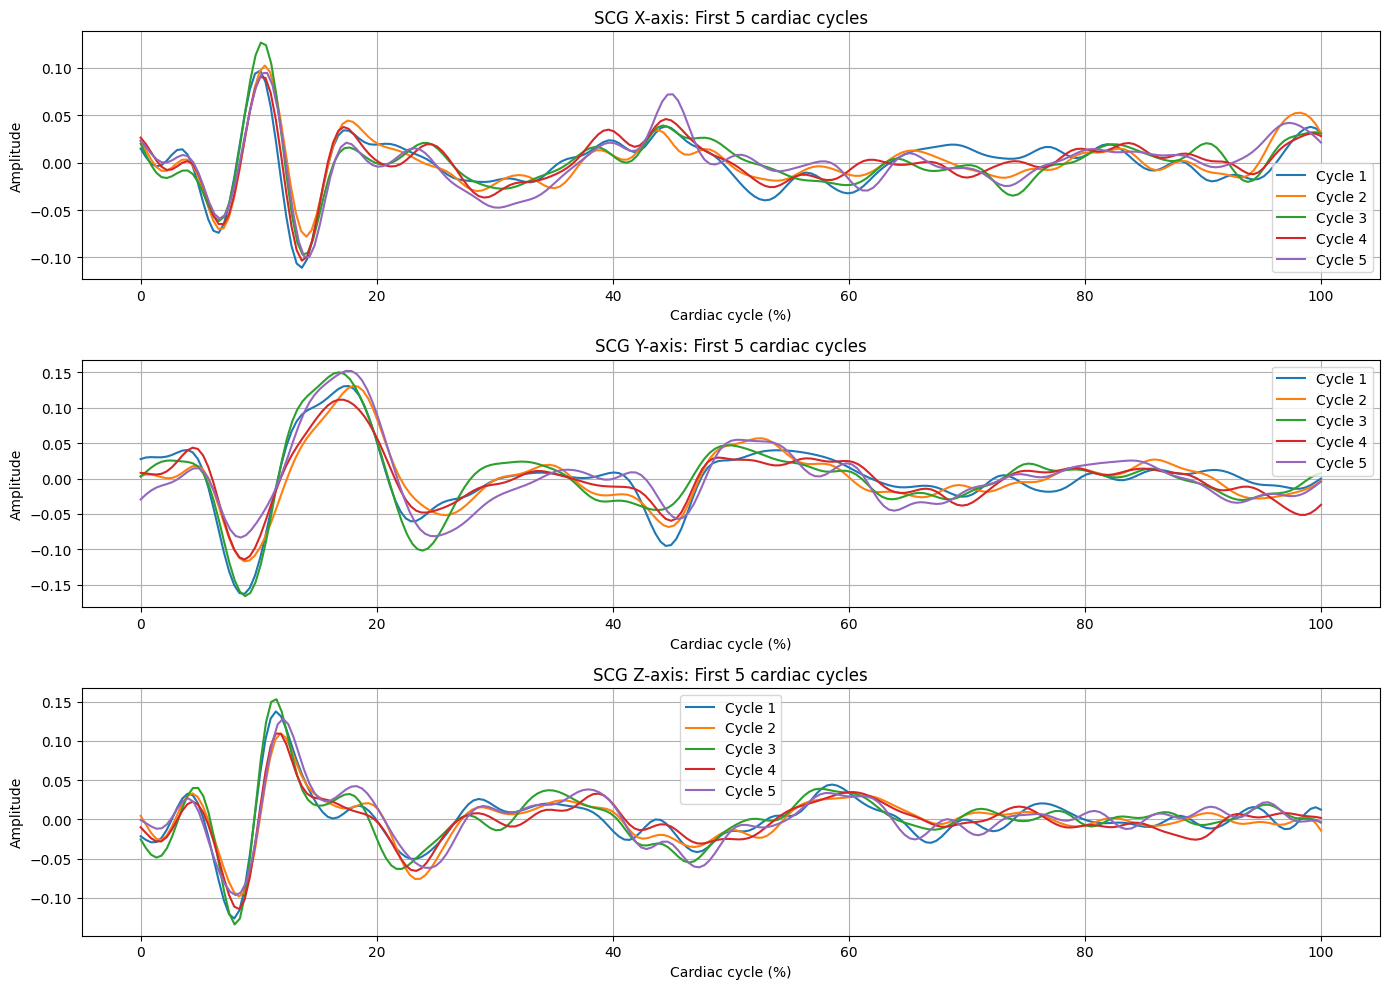

In [34]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

for ax, axis in zip(axes, ["X", "Y", "Z"]):

    for i in range(5):
        cycle = scg_cycles[axis][i]

        # Normalize each cycle to percentage of cardiac cycle
        time_percent = np.linspace(0, 100, len(cycle))

        ax.plot(time_percent, cycle, label=f"Cycle {i+1}")

    ax.set_title(f"SCG {axis}-axis: First 5 cardiac cycles")
    ax.set_xlabel("Cardiac cycle (%)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


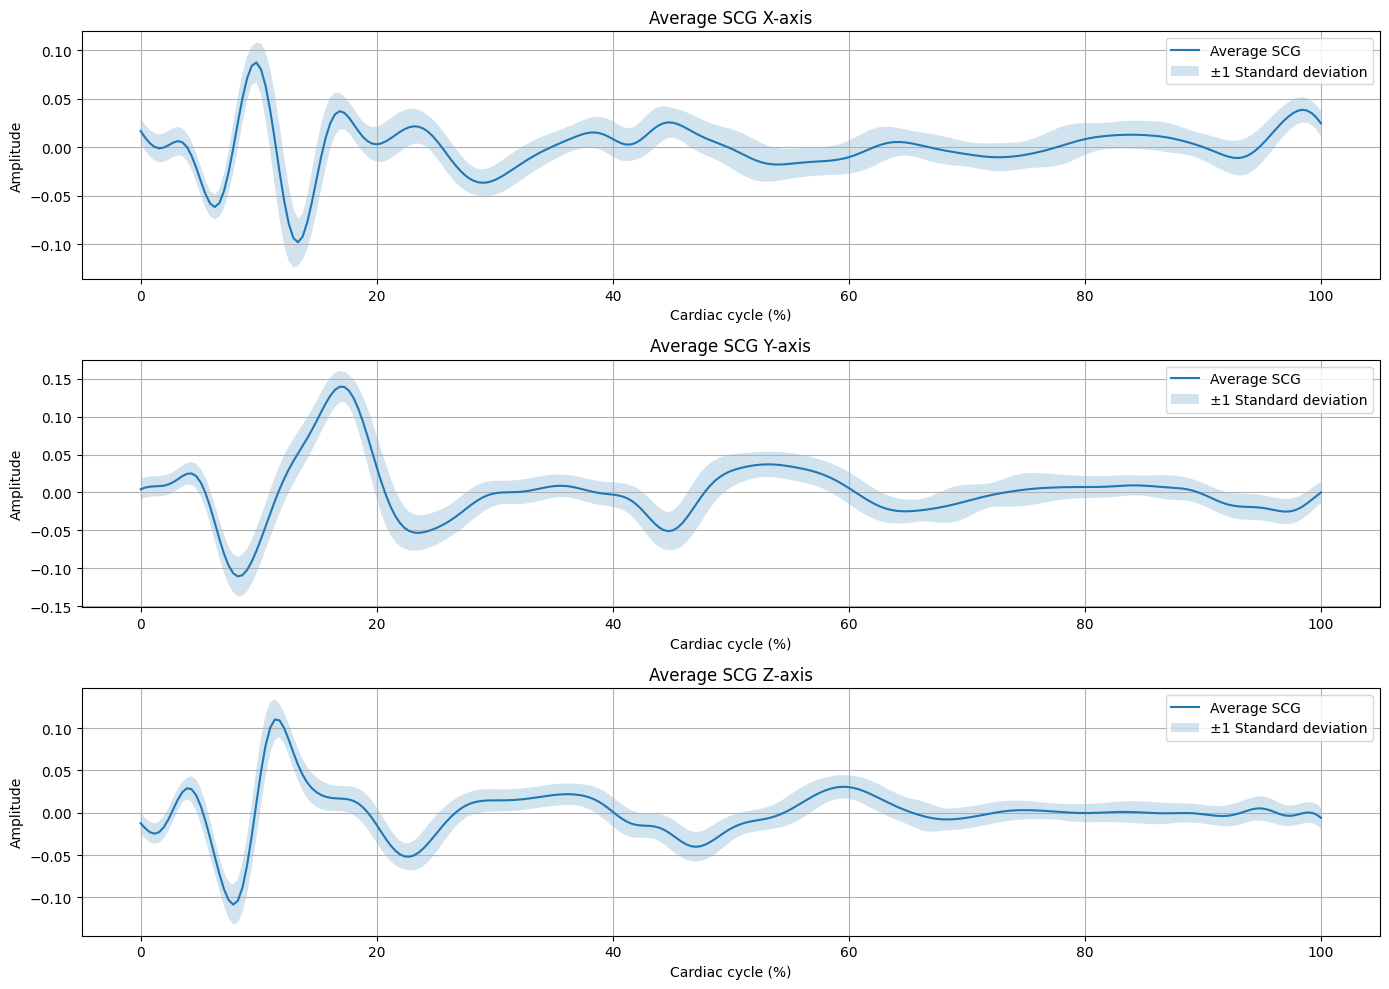

In [35]:

import numpy as np
import matplotlib.pyplot as plt

# Resample every cycle to 256 points
# This gives every cycle the same length.
n_points = 256

normalized_cycles = {}

for axis in ["X", "Y", "Z"]:
    normalized_cycles[axis] = np.array([
        np.interp(
            np.linspace(0, len(cycle)-1, n_points),
            np.arange(len(cycle)),
            cycle
        )
        for cycle in scg_cycles[axis]
    ])

# Calculate mean and standard deviation
average_scg = {}
std_scg = {}

for axis in ["X", "Y", "Z"]:
    average_scg[axis] = np.mean(normalized_cycles[axis], axis=0)
    std_scg[axis] = np.std(normalized_cycles[axis], axis=0)

# Plot average waveforms
time_percent = np.linspace(0, 100, n_points)

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

for ax, axis in zip(axes, ["X", "Y", "Z"]):
    ax.plot(time_percent, average_scg[axis], label="Average SCG")
    ax.fill_between(
        time_percent,
        average_scg[axis] - std_scg[axis],
        average_scg[axis] + std_scg[axis],
        alpha=0.2,
        label="±1 Standard deviation"
    )

    ax.set_title(f"Average SCG {axis}-axis")
    ax.set_xlabel("Cardiac cycle (%)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


===== CP-01 CARDIAC CYCLE ANALYSIS =====
Total cycles: 522
Mean duration: 882.37 ms
Median duration: 882.81 ms
Minimum duration: 707.03 ms
Maximum duration: 933.59 ms
Standard deviation: 22.13 ms


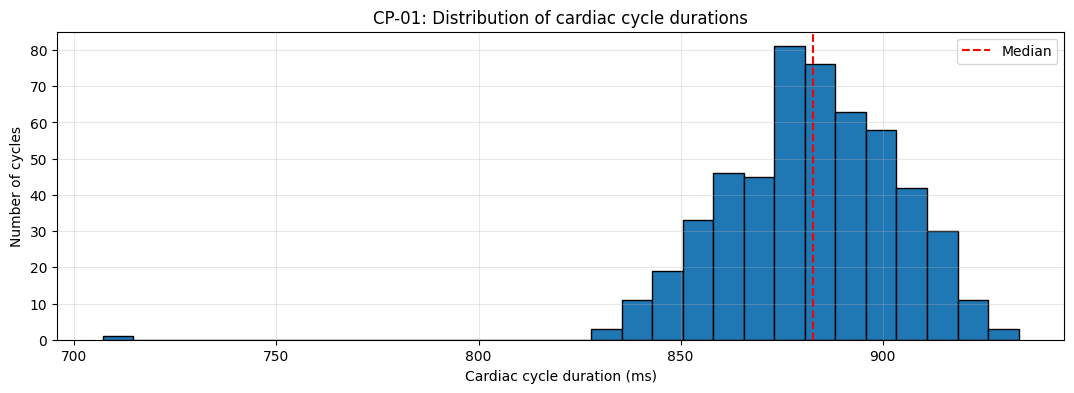

In [38]:

import numpy as np
import matplotlib.pyplot as plt

# Calculate duration of each cardiac cycle
rr_intervals = np.diff(r_times) * 1000  # milliseconds

print("===== CP-01 CARDIAC CYCLE ANALYSIS =====")
print("Total cycles:", len(rr_intervals))
print("Mean duration:", round(np.mean(rr_intervals), 2), "ms")
print("Median duration:", round(np.median(rr_intervals), 2), "ms")
print("Minimum duration:", round(np.min(rr_intervals), 2), "ms")
print("Maximum duration:", round(np.max(rr_intervals), 2), "ms")
print("Standard deviation:", round(np.std(rr_intervals), 2), "ms")

# Visualize cycle durations
plt.figure(figsize=(13, 4))
plt.hist(rr_intervals, bins=30, edgecolor="black")
plt.axvline(np.median(rr_intervals), color="red",
            linestyle="--", label="Median")
plt.xlabel("Cardiac cycle duration (ms)")
plt.ylabel("Number of cycles")
plt.title("CP-01: Distribution of cardiac cycle durations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [39]:

import numpy as np

median_rr = np.median(rr_intervals)
mad = np.median(np.abs(rr_intervals - median_rr))

# Robust outlier score
robust_z = (
    0.6745 * (rr_intervals - median_rr) / mad
    if mad > 0 else np.zeros_like(rr_intervals)
)

outlier_indices = np.where(np.abs(robust_z) > 3.5)[0]

print("===== UNUSUAL CARDIAC CYCLES =====")
print("Number flagged:", len(outlier_indices))

for idx in outlier_indices:
    print(
        f"Cycle {idx + 1}: "
        f"{rr_intervals[idx]:.2f} ms, "
        f"robust Z = {robust_z[idx]:.2f}"
    )

# Keep all cycles; only create a flag for later inspection
cycle_quality_flags = np.ones(len(rr_intervals), dtype=bool)
cycle_quality_flags[outlier_indices] = False


===== UNUSUAL CARDIAC CYCLES =====
Number flagged: 1
Cycle 331: 707.03 ms, robust Z = -7.59


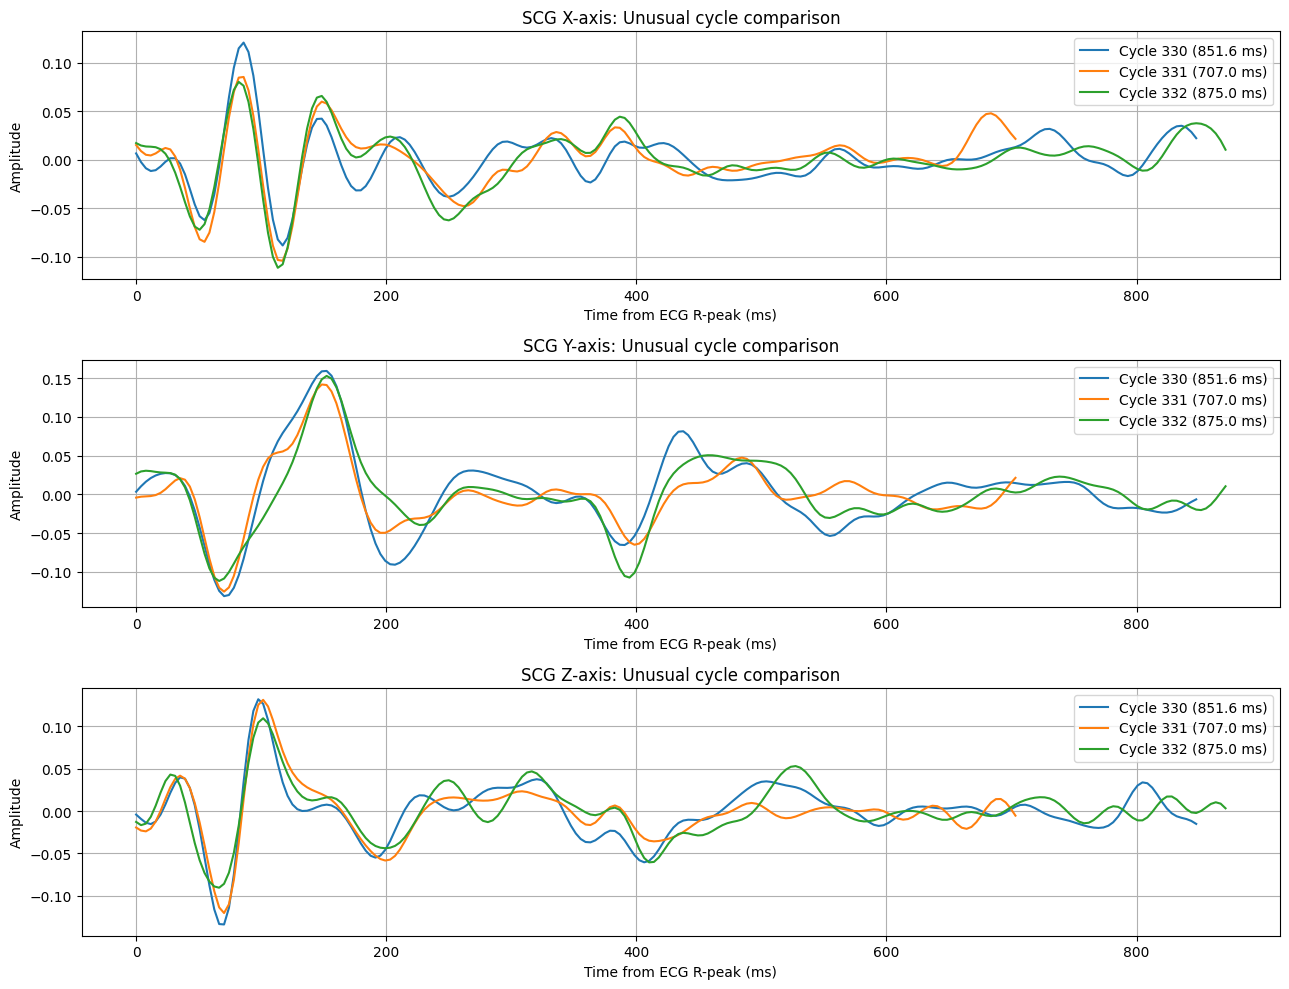

In [40]:

import matplotlib.pyplot as plt
import numpy as np

cycles_to_check = [329, 330, 331]  # Python indices: cycles 330, 331, 332

fig, axes = plt.subplots(3, 1, figsize=(13, 10))

for ax, axis in zip(axes, ["X", "Y", "Z"]):

    for idx in cycles_to_check:
        cycle = scg_cycles[axis][idx]
        time_ms = np.arange(len(cycle)) / fs * 1000

        ax.plot(
            time_ms,
            cycle,
            label=f"Cycle {idx + 1} ({len(cycle)/fs*1000:.1f} ms)"
        )

    ax.set_title(f"SCG {axis}-axis: Unusual cycle comparison")
    ax.set_xlabel("Time from ECG R-peak (ms)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


In [41]:

import numpy as np
from scipy.stats import pearsonr

# Compare cycle 331 with cycles 330 and 332
target_idx = 330
comparison_indices = [329, 331]

def resample_cycle(cycle, n=256):
    return np.interp(
        np.linspace(0, len(cycle)-1, n),
        np.arange(len(cycle)),
        cycle
    )

print("===== CYCLE 331 SIMILARITY =====")

for axis in ["X", "Y", "Z"]:
    target = resample_cycle(scg_cycles[axis][target_idx])

    for idx in comparison_indices:
        other = resample_cycle(scg_cycles[axis][idx])

        correlation = pearsonr(target, other).statistic

        print(
            f"SCG {axis}: Cycle 331 vs Cycle {idx+1}: "
            f"Correlation = {correlation:.4f}"
        )


===== CYCLE 331 SIMILARITY =====
SCG X: Cycle 331 vs Cycle 330: Correlation = -0.0153
SCG X: Cycle 331 vs Cycle 332: Correlation = -0.2227
SCG Y: Cycle 331 vs Cycle 330: Correlation = 0.2694
SCG Y: Cycle 331 vs Cycle 332: Correlation = 0.3841
SCG Z: Cycle 331 vs Cycle 330: Correlation = 0.0239
SCG Z: Cycle 331 vs Cycle 332: Correlation = 0.0008


In [42]:

import numpy as np
import pandas as pd

quality_data = []

for i in range(len(scg_cycles["X"])):

    rms_x = np.sqrt(np.mean(scg_cycles["X"][i] ** 2))
    rms_y = np.sqrt(np.mean(scg_cycles["Y"][i] ** 2))
    rms_z = np.sqrt(np.mean(scg_cycles["Z"][i] ** 2))

    combined_rms = np.sqrt(
        (rms_x**2 + rms_y**2 + rms_z**2) / 3
    )

    quality_data.append({
        "Cycle": i + 1,
        "Duration_ms": rr_intervals[i],
        "RMS_X": rms_x,
        "RMS_Y": rms_y,
        "RMS_Z": rms_z,
        "Combined_RMS": combined_rms
    })

quality_df = pd.DataFrame(quality_data)

print("===== SCG QUALITY SUMMARY =====")
print(quality_df.describe().round(5))

print("\nCycle 331:")
print(quality_df.iloc[330].to_string())


===== SCG QUALITY SUMMARY =====
           Cycle  Duration_ms      RMS_X      RMS_Y      RMS_Z  Combined_RMS
count  522.00000    522.00000  522.00000  522.00000  522.00000     522.00000
mean   261.50000    882.37099    0.02975    0.04327    0.03250       0.03579
std    150.83269     22.15422    0.00731    0.00799    0.00457       0.00606
min      1.00000    707.03125    0.02334    0.03089    0.02302       0.02797
25%    131.25000    867.18750    0.02751    0.03874    0.03011       0.03310
50%    261.50000    882.81250    0.02865    0.04187    0.03206       0.03482
75%    391.75000    898.43750    0.03009    0.04595    0.03403       0.03658
max    522.00000    933.59375    0.12763    0.12020    0.07026       0.10452

Cycle 331:
Cycle           331.000000
Duration_ms     707.031250
RMS_X             0.031174
RMS_Y             0.042753
RMS_Z             0.034696
Combined_RMS      0.036531


In [43]:

import numpy as np

rms_values = quality_df["Combined_RMS"].to_numpy()

median_rms = np.median(rms_values)
mad_rms = np.median(np.abs(rms_values - median_rms))

robust_rms_z = (
    0.6745 * (rms_values - median_rms) / mad_rms
    if mad_rms > 0 else np.zeros_like(rms_values)
)

high_rms_indices = np.where(robust_rms_z > 3.5)[0]

print("===== HIGH-AMPLITUDE SCG CYCLES =====")
print("Cycles flagged:", len(high_rms_indices))

for idx in high_rms_indices:
    print(
        f"Cycle {idx + 1}: "
        f"Combined RMS = {rms_values[idx]:.5f}, "
        f"Robust Z = {robust_rms_z[idx]:.2f}"
    )

print("\nCycle 331 RMS robust Z-score:",
      round(robust_rms_z[330], 3))


===== HIGH-AMPLITUDE SCG CYCLES =====
Cycles flagged: 23
Cycle 20: Combined RMS = 0.04866, Robust Z = 5.37
Cycle 21: Combined RMS = 0.08187, Robust Z = 18.27
Cycle 22: Combined RMS = 0.05576, Robust Z = 8.13
Cycle 23: Combined RMS = 0.06732, Robust Z = 12.62
Cycle 24: Combined RMS = 0.06850, Robust Z = 13.08
Cycle 25: Combined RMS = 0.10452, Robust Z = 27.06
Cycle 26: Combined RMS = 0.06951, Robust Z = 13.47
Cycle 28: Combined RMS = 0.04483, Robust Z = 3.89
Cycle 29: Combined RMS = 0.04844, Robust Z = 5.29
Cycle 30: Combined RMS = 0.05794, Robust Z = 8.98
Cycle 36: Combined RMS = 0.04504, Robust Z = 3.97
Cycle 37: Combined RMS = 0.04527, Robust Z = 4.06
Cycle 38: Combined RMS = 0.07542, Robust Z = 15.77
Cycle 39: Combined RMS = 0.04576, Robust Z = 4.25
Cycle 42: Combined RMS = 0.06132, Robust Z = 10.29
Cycle 45: Combined RMS = 0.04924, Robust Z = 5.60
Cycle 46: Combined RMS = 0.04708, Robust Z = 4.76
Cycle 118: Combined RMS = 0.04549, Robust Z = 4.14
Cycle 144: Combined RMS = 0.05892, 

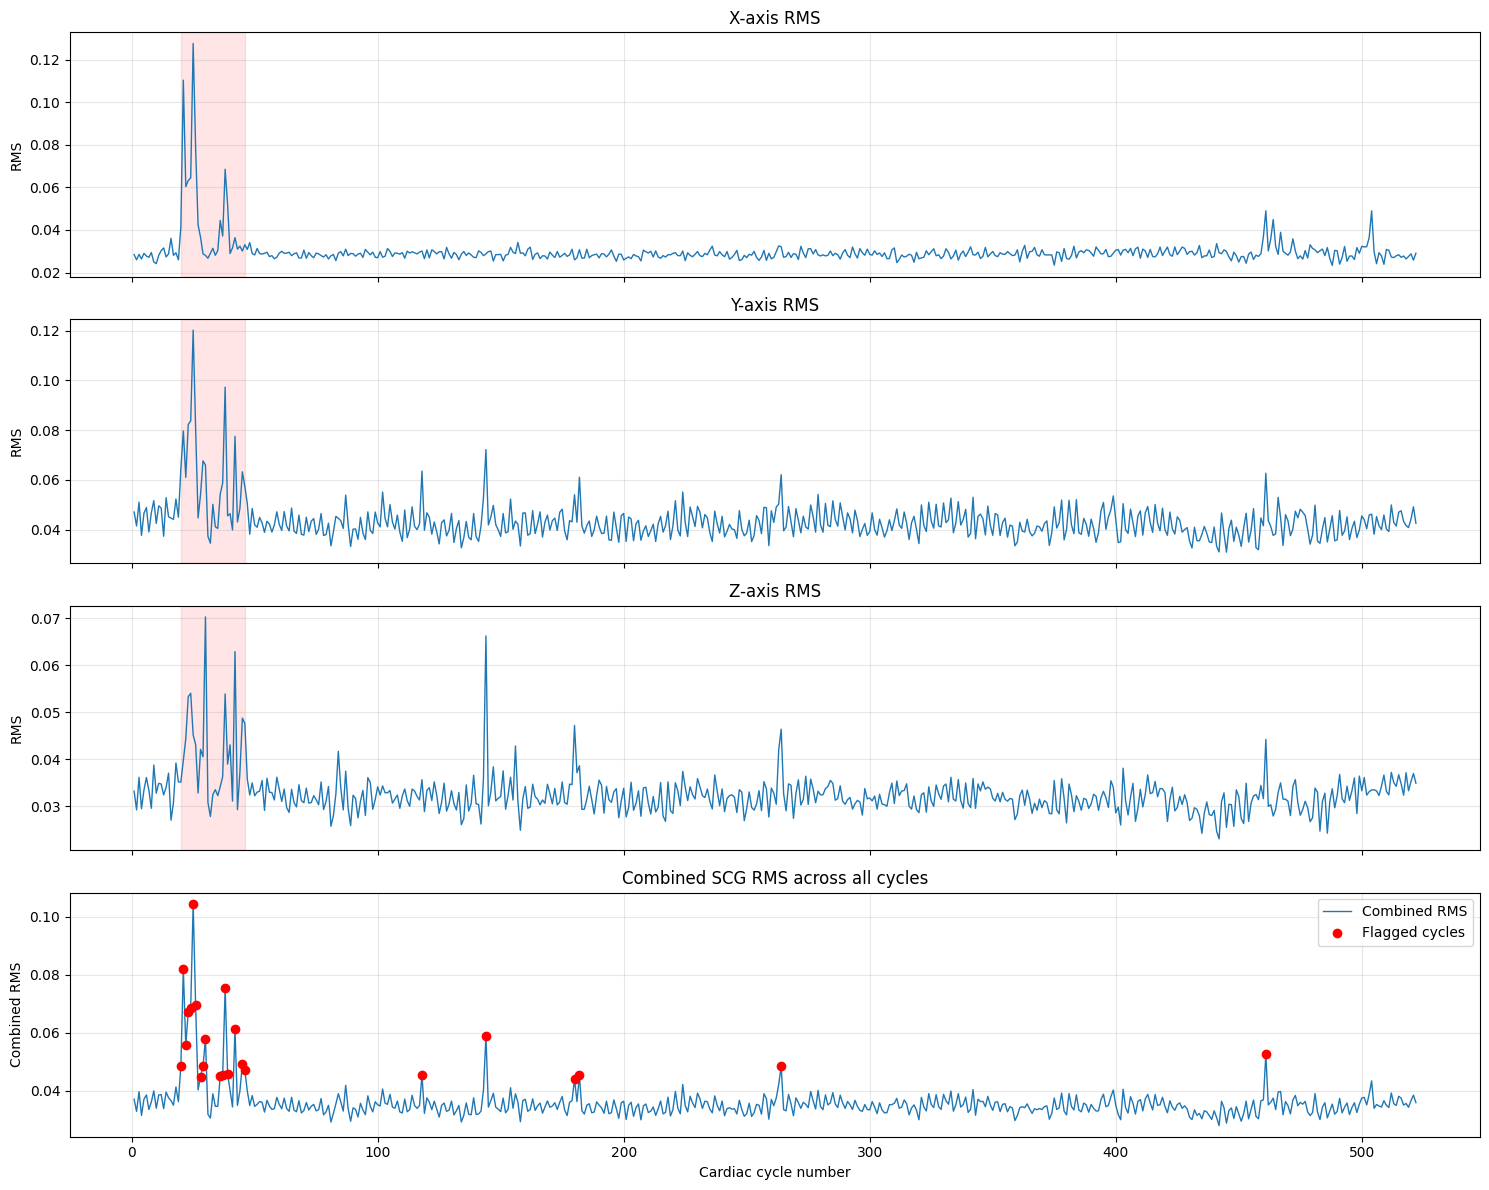

In [44]:

import matplotlib.pyplot as plt
import numpy as np

cycle_numbers = quality_df["Cycle"].to_numpy()

fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

for ax, column, label in zip(
    axes[:3],
    ["RMS_X", "RMS_Y", "RMS_Z"],
    ["X-axis RMS", "Y-axis RMS", "Z-axis RMS"]
):
    ax.plot(cycle_numbers, quality_df[column], linewidth=1)
    ax.set_ylabel("RMS")
    ax.set_title(label)
    ax.grid(alpha=0.3)

    ax.axvspan(20, 46, color="red", alpha=0.10)

axes[3].plot(
    cycle_numbers,
    quality_df["Combined_RMS"],
    label="Combined RMS",
    linewidth=1
)

axes[3].scatter(
    high_rms_indices + 1,
    rms_values[high_rms_indices],
    color="red",
    label="Flagged cycles",
    zorder=3
)

axes[3].set_title("Combined SCG RMS across all cycles")
axes[3].set_xlabel("Cardiac cycle number")
axes[3].set_ylabel("Combined RMS")
axes[3].legend()
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()


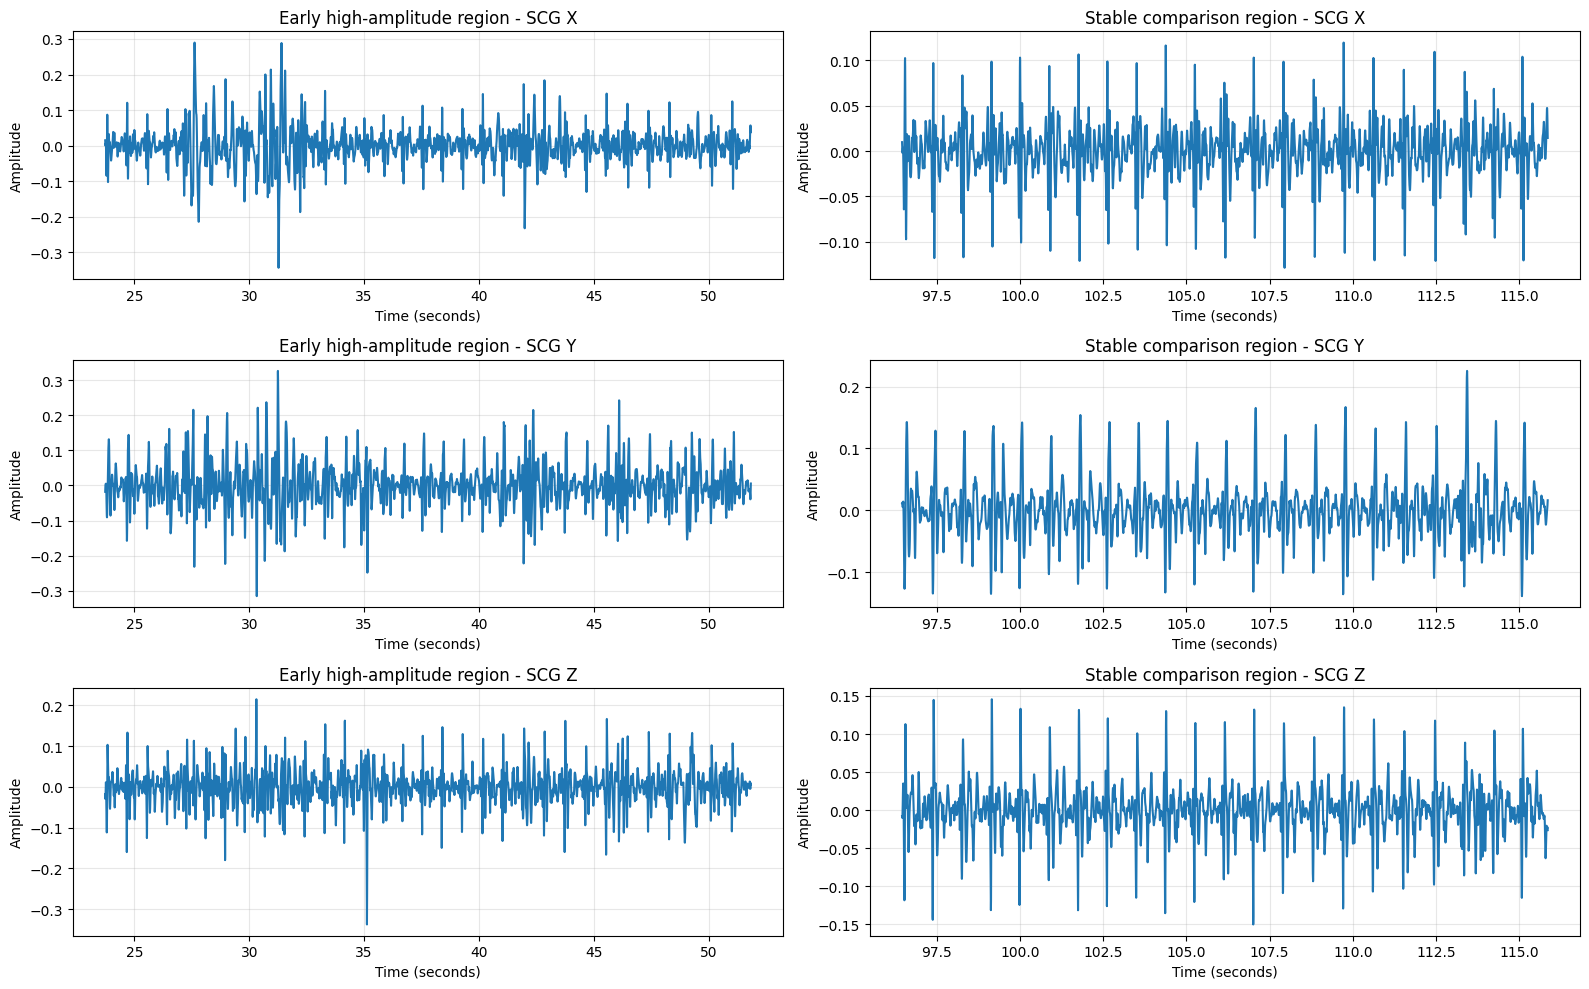

In [45]:

import matplotlib.pyplot as plt
import numpy as np

regions = {
    "Early high-amplitude region": (17, 48),
    "Stable comparison region": (99, 120)
}

fig, axes = plt.subplots(3, 2, figsize=(16, 10))

for col, (region_name, (start_cycle, end_cycle)) in enumerate(regions.items()):

    start_sample = r_samples[start_cycle - 1]
    end_sample = r_samples[end_cycle]

    time_axis = np.arange(start_sample, end_sample) / fs
    signals = [scg_x_filtered, scg_y_filtered, scg_z_filtered]

    for row, (signal, axis_name) in enumerate(
        zip(signals, ["X", "Y", "Z"])
    ):
        axes[row, col].plot(time_axis, signal[start_sample:end_sample])
        axes[row, col].set_title(f"{region_name} - SCG {axis_name}")
        axes[row, col].set_xlabel("Time (seconds)")
        axes[row, col].set_ylabel("Amplitude")
        axes[row, col].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [46]:

import numpy as np
import pandas as pd

regions = {
    "Early region (Cycles 18-48)": (17, 48),
    "Stable region (Cycles 100-120)": (99, 120)
}

signals = {
    "X": scg_x_filtered,
    "Y": scg_y_filtered,
    "Z": scg_z_filtered
}

results = []

for region_name, (start_cycle, end_cycle) in regions.items():

    start = r_samples[start_cycle]
    end = r_samples[end_cycle]

    for axis, signal in signals.items():

        segment = signal[start:end]

        rms = np.sqrt(np.mean(segment ** 2))
        peak_to_peak = np.max(segment) - np.min(segment)

        results.append({
            "Region": region_name,
            "Axis": axis,
            "RMS": rms,
            "Peak_to_Peak": peak_to_peak
        })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(5).to_string(index=False))


                        Region Axis     RMS  Peak_to_Peak
   Early region (Cycles 18-48)    X 0.05006       0.63345
   Early region (Cycles 18-48)    Y 0.06184       0.64160
   Early region (Cycles 18-48)    Z 0.04187       0.55238
Stable region (Cycles 100-120)    X 0.02894       0.24773
Stable region (Cycles 100-120)    Y 0.04443       0.36381
Stable region (Cycles 100-120)    Z 0.03235       0.29569


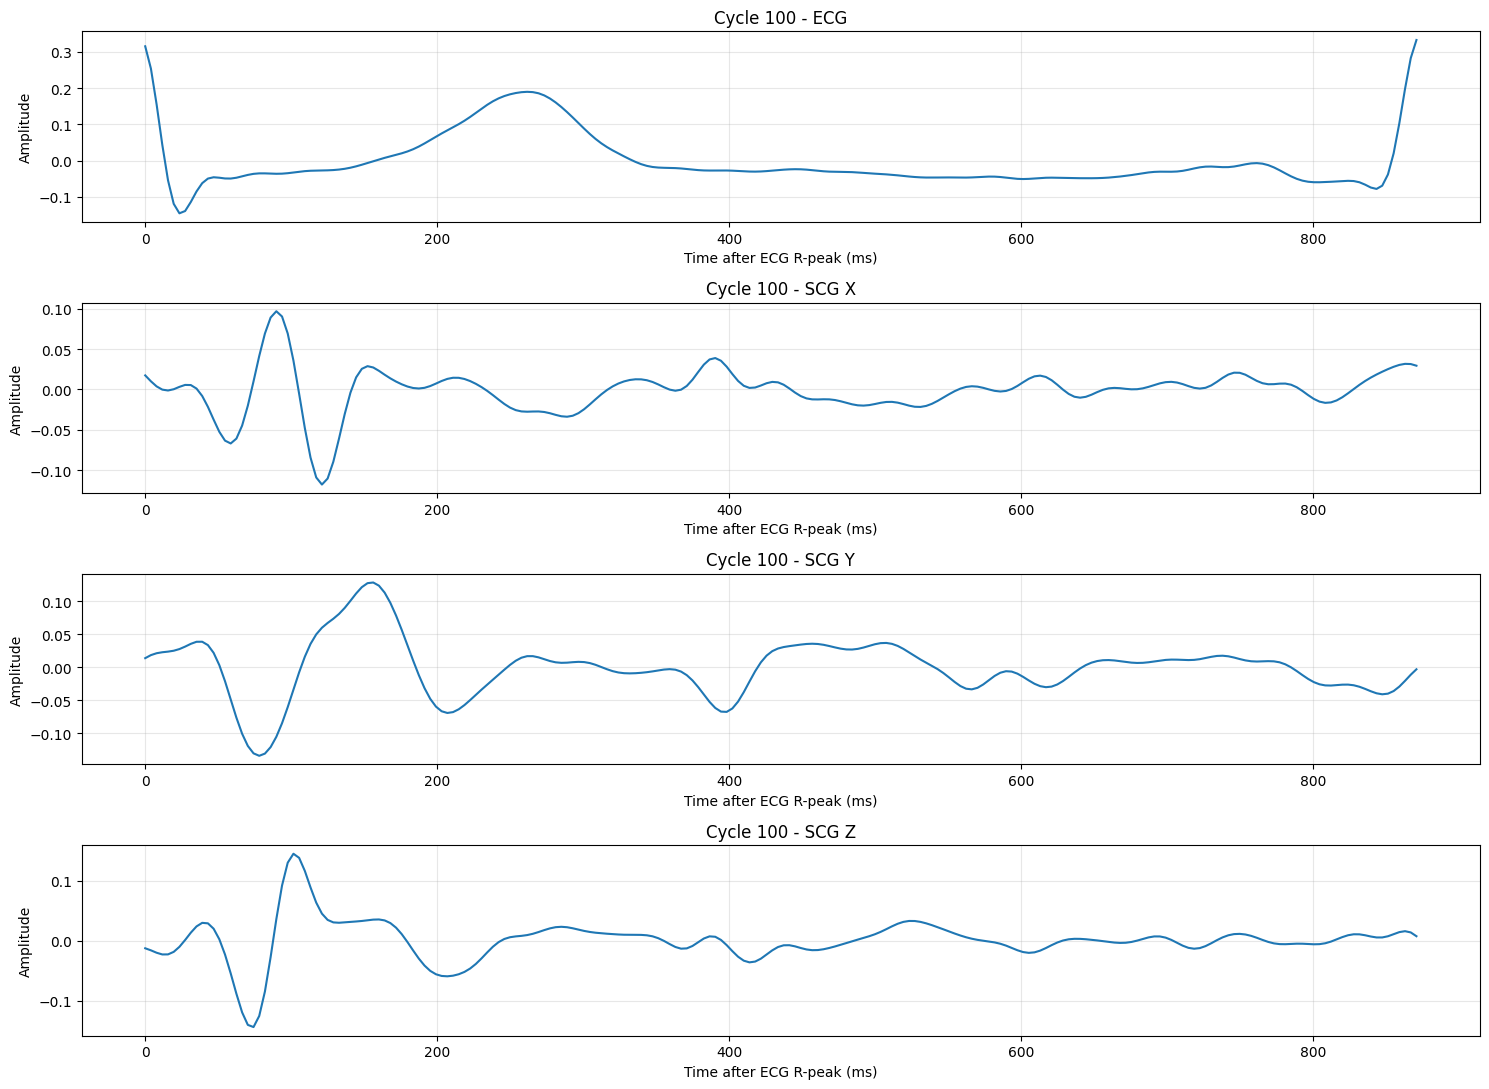

Cycle duration: 875.0 ms


In [47]:

import matplotlib.pyplot as plt
import numpy as np

cycle_idx = 99  # Cycle 100

fig, axes = plt.subplots(4, 1, figsize=(15, 11))

signals = [
    (ecg_filtered, "ECG"),
    (scg_x_filtered, "SCG X"),
    (scg_y_filtered, "SCG Y"),
    (scg_z_filtered, "SCG Z")
]

start = r_samples[cycle_idx]
end = r_samples[cycle_idx + 1]

time_ms = np.arange(end - start) / fs * 1000

for ax, (signal, label) in zip(axes, signals):
    ax.plot(time_ms, signal[start:end])
    ax.set_title(f"Cycle 100 - {label}")
    ax.set_xlabel("Time after ECG R-peak (ms)")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Cycle duration:",
      round((r_times[cycle_idx + 1] - r_times[cycle_idx]) * 1000, 2),
      "ms")


In [48]:

import numpy as np
import pandas as pd
from scipy.signal import find_peaks

cycle_idx = 99
results = []

for axis in ["X", "Y", "Z"]:

    cycle = scg_cycles[axis][cycle_idx]

    # Find positive peaks
    positive_peaks, _ = find_peaks(
        cycle,
        prominence=0.005,
        distance=int(0.02 * fs)
    )

    # Find negative peaks (valleys)
    negative_peaks, _ = find_peaks(
        -cycle,
        prominence=0.005,
        distance=int(0.02 * fs)
    )

    for p in positive_peaks:
        results.append({
            "Axis": axis,
            "Type": "Positive peak",
            "Time_ms": round(p / fs * 1000, 2),
            "Amplitude": round(cycle[p], 5)
        })

    for p in negative_peaks:
        results.append({
            "Axis": axis,
            "Type": "Negative peak",
            "Time_ms": round(p / fs * 1000, 2),
            "Amplitude": round(cycle[p], 5)
        })

candidate_df = pd.DataFrame(results)
candidate_df = candidate_df.sort_values(
    ["Axis", "Time_ms"]
).reset_index(drop=True)

print("===== CYCLE 100: CANDIDATE FEATURES =====")
print(candidate_df.to_string(index=False))


===== CYCLE 100: CANDIDATE FEATURES =====
Axis          Type  Time_ms  Amplitude
   X Negative peak    15.62   -0.00136
   X Positive peak    27.34    0.00555
   X Negative peak    58.59   -0.06694
   X Positive peak    89.84    0.09675
   X Negative peak   121.09   -0.11780
   X Positive peak   152.34    0.02877
   X Negative peak   187.50    0.00112
   X Positive peak   210.94    0.01441
   X Negative peak   289.06   -0.03383
   X Positive peak   335.94    0.01251
   X Negative peak   363.28   -0.00165
   X Positive peak   390.62    0.03881
   X Negative peak   414.06    0.00184
   X Positive peak   429.69    0.00929
   X Negative peak   531.25   -0.02170
   X Positive peak   566.41    0.00390
   X Negative peak   585.94   -0.00260
   X Positive peak   613.28    0.01705
   X Negative peak   640.62   -0.01025
   X Positive peak   703.12    0.00936
   X Negative peak   722.66    0.00101
   X Positive peak   746.09    0.02069
   X Negative peak   808.59   -0.01664
   Y Positive peak    

In [49]:

print("===== AVAILABLE SIGNAL VARIABLES =====")

for name, value in globals().copy().items():
    if isinstance(value, np.ndarray):
        if value.ndim == 1 and len(value) > 1000:
            print(f"{name}: {value.shape}, {value.dtype}")


===== AVAILABLE SIGNAL VARIABLES =====
signal: (124838,), float64
timestamp: (124838,), float64
ecg: (124838,), float64
scg_x: (124838,), float64
scg_y: (124838,), float64
scg_z: (124838,), float64
time: (2560,), float64
sig: (124838,), float64
ecg_filtered: (124838,), float64
scg_x_filtered: (124838,), float64
scg_y_filtered: (124838,), float64
scg_z_filtered: (124838,), float64
t: (2560,), float64
segment: (4748,), float64
time_axis: (4965,), float64


In [50]:

import numpy as np

variables = {
    "signal": signal,
    "sig": sig,
    "ecg": ecg,
    "SCG_X": scg_x,
    "SCG_Y": scg_y,
    "SCG_Z": scg_z
}

print("===== SIGNAL IDENTITY CHECK =====")

for name in ["signal", "sig"]:
    print(f"\n{name}:")

    for other_name in ["ecg", "SCG_X", "SCG_Y", "SCG_Z"]:
        a = variables[name]
        b = variables[other_name]

        if len(a) == len(b):
            correlation = np.corrcoef(a, b)[0, 1]
            identical = np.allclose(a, b)

            print(
                f"Compared with {other_name}: "
                f"Correlation={correlation:.5f}, "
                f"Identical={identical}"
            )


===== SIGNAL IDENTITY CHECK =====

signal:
Compared with ecg: Correlation=-0.00239, Identical=False
Compared with SCG_X: Correlation=-0.05918, Identical=False
Compared with SCG_Y: Correlation=0.17032, Identical=False
Compared with SCG_Z: Correlation=0.67756, Identical=False

sig:
Compared with ecg: Correlation=-0.00239, Identical=False
Compared with SCG_X: Correlation=-0.05918, Identical=False
Compared with SCG_Y: Correlation=0.17032, Identical=False
Compared with SCG_Z: Correlation=0.67756, Identical=False


In [51]:

from scipy.io import loadmat
import numpy as np

mat = loadmat("/content/CP-01-Vectors.mat")

print("===== ORIGINAL MAT-FILE CONTENTS =====")

for name, value in mat.items():
    if name.startswith("__"):
        continue

    if isinstance(value, np.ndarray):
        print(
            f"{name}: shape={value.shape}, "
            f"dtype={value.dtype}"
        )
    else:
        print(name, type(value))


===== ORIGINAL MAT-FILE CONTENTS =====
Shimmer_D0CD_Accel_LN_X_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Accel_LN_Y_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Accel_LN_Z_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_EMG_Status1_CAL1: shape=(124838, 1), dtype=uint8
Shimmer_D0CD_ECG_EMG_Status2_CAL1: shape=(124838, 1), dtype=uint8
Shimmer_D0CD_ECG_LARA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_LLLA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_LLRA_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_ECG_VxRL_24BIT_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_X_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_Y_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Gyro_Z_CAL1: shape=(124838, 1), dtype=float64
Shimmer_D0CD_Timestamp_Shimmer_CAL1: shape=(124838, 1), dtype=float64
None: shape=(1,), dtype=[('s0', 'O'), ('s1', 'O'), ('s2', 'O'), ('arr', 'O')]


===== GYROSCOPE CHANNELS =====
Gyroscope X | Samples: 124838 | Mean: 0.16837 | Std: 1.1592 | Min: -59.55725 | Max: 104.50382
Gyroscope Y | Samples: 124838 | Mean: 0.03522 | Std: 1.43592 | Min: -262.8855 | Max: 62.94656
Gyroscope Z | Samples: 124838 | Mean: 0.25067 | Std: 1.30455 | Min: -140.83969 | Max: 50.50382


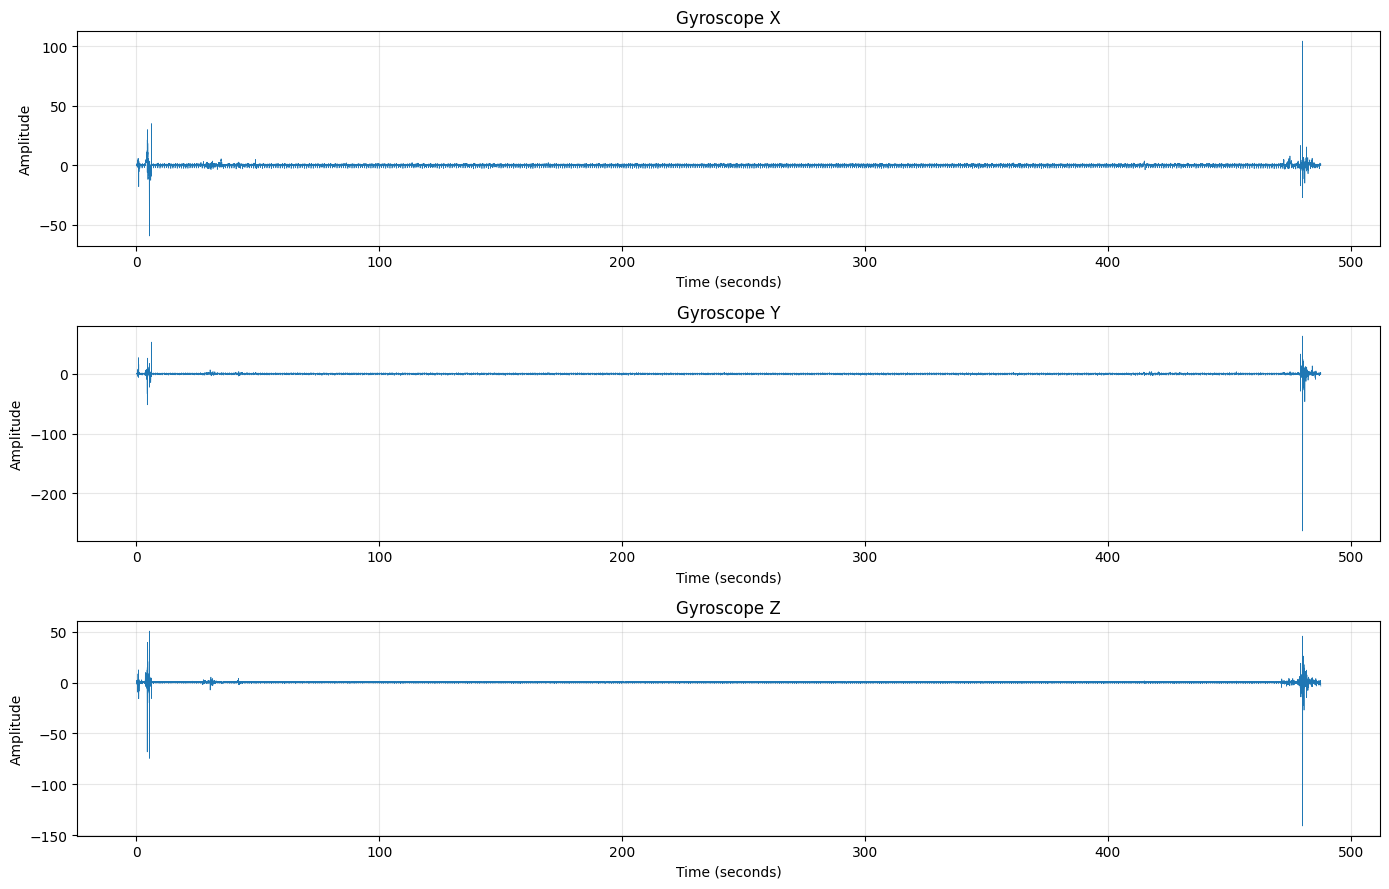

In [52]:

# Extract gyroscope channels from the original MAT file

gyro_x = mat["Shimmer_D0CD_Gyro_X_CAL1"].flatten()
gyro_y = mat["Shimmer_D0CD_Gyro_Y_CAL1"].flatten()
gyro_z = mat["Shimmer_D0CD_Gyro_Z_CAL1"].flatten()

print("===== GYROSCOPE CHANNELS =====")

for name, sig in [
    ("Gyroscope X", gyro_x),
    ("Gyroscope Y", gyro_y),
    ("Gyroscope Z", gyro_z)
]:
    print(
        name,
        "| Samples:", len(sig),
        "| Mean:", round(np.mean(sig), 5),
        "| Std:", round(np.std(sig), 5),
        "| Min:", round(np.min(sig), 5),
        "| Max:", round(np.max(sig), 5)
    )

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(14, 9))

for ax, sig, name in zip(
    axes,
    [gyro_x, gyro_y, gyro_z],
    ["Gyroscope X", "Gyroscope Y", "Gyroscope Z"]
):
    ax.plot(np.arange(len(sig)) / fs, sig, linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


===== GYROSCOPE STATISTICS =====
Gyro X: Mean=0.16837, Std=1.15920, Min=-59.55725, Max=104.50382
Gyro Y: Mean=0.03522, Std=1.43592, Min=-262.88550, Max=62.94656
Gyro Z: Mean=0.25067, Std=1.30455, Min=-140.83969, Max=50.50382


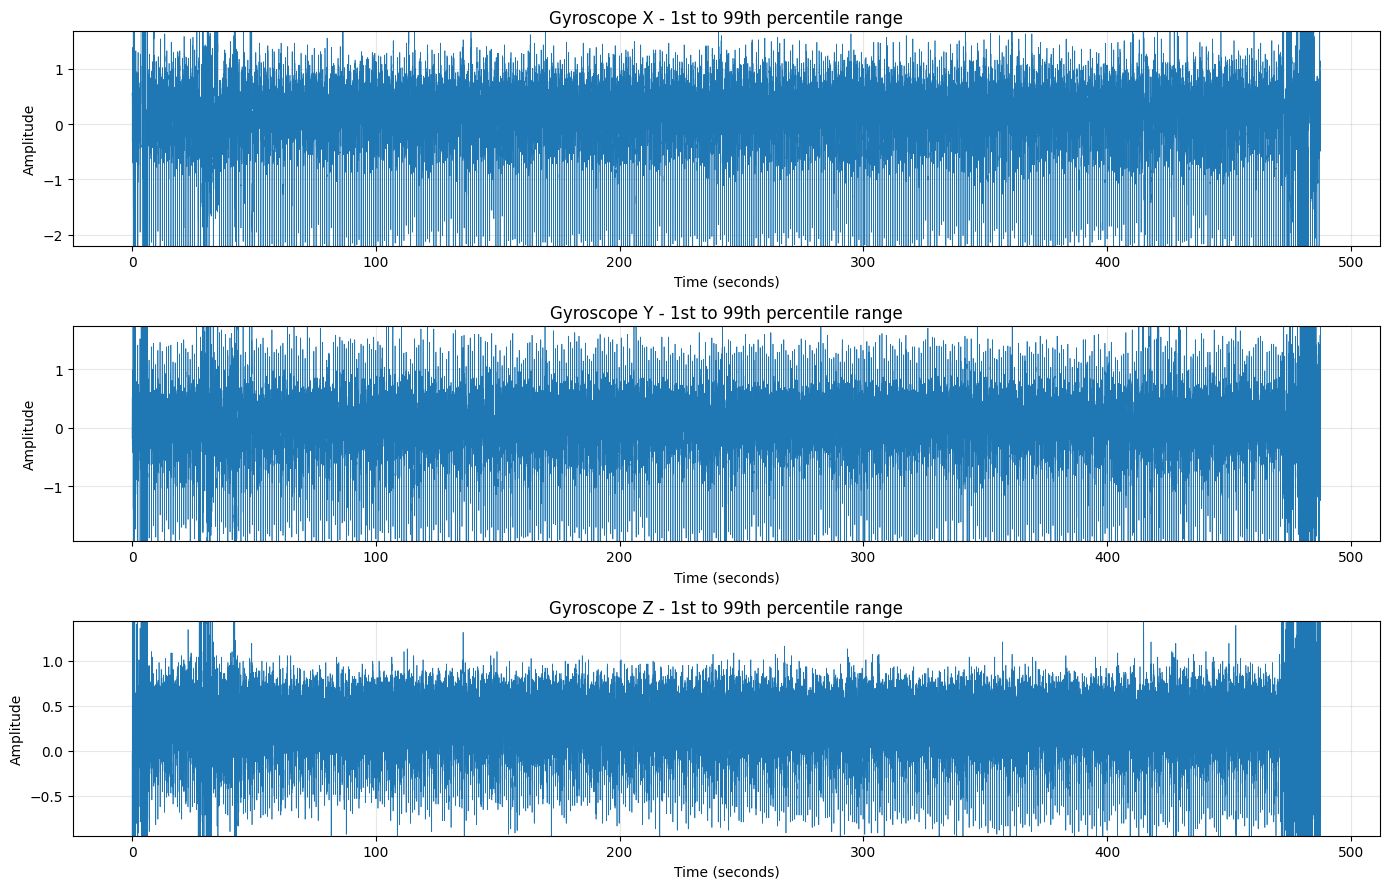

In [53]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

gyro_signals = {
    "X": gyro_x,
    "Y": gyro_y,
    "Z": gyro_z
}

print("===== GYROSCOPE STATISTICS =====")

for axis, values in gyro_signals.items():
    print(
        f"Gyro {axis}: "
        f"Mean={np.mean(values):.5f}, "
        f"Std={np.std(values):.5f}, "
        f"Min={np.min(values):.5f}, "
        f"Max={np.max(values):.5f}"
    )

# Plot all axes using robust percentile limits
fig, axes = plt.subplots(3, 1, figsize=(14, 9))

for ax, (axis, values) in zip(axes, gyro_signals.items()):
    lower, upper = np.percentile(values, [1, 99])

    ax.plot(np.arange(len(values)) / fs, values, linewidth=0.5)
    ax.set_ylim(lower, upper)
    ax.set_title(f"Gyroscope {axis} - 1st to 99th percentile range")
    ax.set_ylabel("Amplitude")
    ax.set_xlabel("Time (seconds)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


===== GYROSCOPE CYCLE SUMMARY =====
           Cycle   Gyro_RMS   Gyro_P95
count  522.00000  522.00000  522.00000
mean   261.50000    0.51235    1.56506
std    150.83269    0.11762    0.43173
min      1.00000    0.42220    1.20970
25%    131.25000    0.46501    1.40885
50%    261.50000    0.49228    1.49059
75%    391.75000    0.51761    1.58473
max    522.00000    1.73085    7.29985


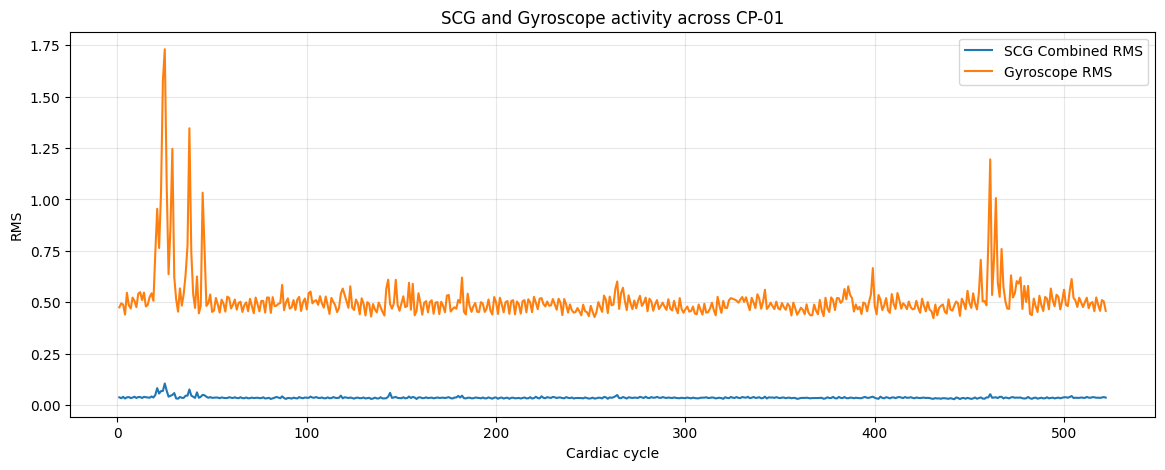

In [54]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

gyro_rows = []

for i in range(len(r_samples) - 1):
    start, end = r_samples[i], r_samples[i + 1]

    gx = gyro_x[start:end]
    gy = gyro_y[start:end]
    gz = gyro_z[start:end]

    # Combined gyroscope RMS
    gyro_rms = np.sqrt(np.mean(
        (gx**2 + gy**2 + gz**2) / 3
    ))

    # Robust activity: 95th percentile absolute magnitude
    gyro_magnitude = np.sqrt(gx**2 + gy**2 + gz**2)
    gyro_p95 = np.percentile(gyro_magnitude, 95)

    gyro_rows.append({
        "Cycle": i + 1,
        "Gyro_RMS": gyro_rms,
        "Gyro_P95": gyro_p95
    })

gyro_quality_df = pd.DataFrame(gyro_rows)

print("===== GYROSCOPE CYCLE SUMMARY =====")
print(gyro_quality_df.describe().round(5))

# Compare gyroscope and SCG activity
plt.figure(figsize=(14, 5))

plt.plot(
    quality_df["Cycle"],
    quality_df["Combined_RMS"],
    label="SCG Combined RMS"
)

plt.plot(
    gyro_quality_df["Cycle"],
    gyro_quality_df["Gyro_RMS"],
    label="Gyroscope RMS"
)

plt.xlabel("Cardiac cycle")
plt.ylabel("RMS")
plt.title("SCG and Gyroscope activity across CP-01")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## **the relationship between SCG and gyroscope activity**

===== SCG-GYROSCOPE RELATIONSHIP =====
Pearson correlation:  0.8038
Pearson p-value:      0.000000
Spearman correlation:0.5511
Spearman p-value:     0.000000


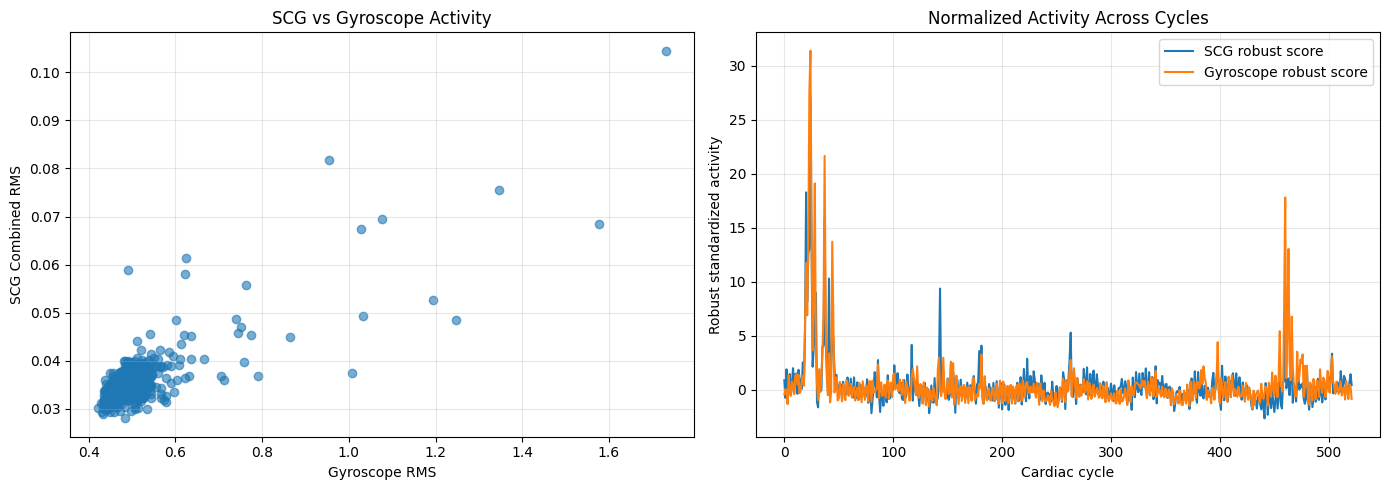

In [55]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

# Match the 522 cardiac cycles
scg_rms = quality_df["Combined_RMS"].to_numpy()
gyro_rms = gyro_quality_df["Gyro_RMS"].to_numpy()

assert len(scg_rms) == len(gyro_rms), "Cycle count mismatch!"

# Statistical relationship
pearson_r, pearson_p = pearsonr(scg_rms, gyro_rms)
spearman_r, spearman_p = spearmanr(scg_rms, gyro_rms)

print("===== SCG-GYROSCOPE RELATIONSHIP =====")
print(f"Pearson correlation:  {pearson_r:.4f}")
print(f"Pearson p-value:      {pearson_p:.6f}")
print(f"Spearman correlation:{spearman_r:.4f}")
print(f"Spearman p-value:     {spearman_p:.6f}")

# Robustly standardize both measurements for visualization
def robust_standardize(values):
    median = np.median(values)
    mad = np.median(np.abs(values - median))
    if mad == 0:
        return values - median
    return 0.6745 * (values - median) / mad

scg_z = robust_standardize(scg_rms)
gyro_z = robust_standardize(gyro_rms)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(gyro_rms, scg_rms, alpha=0.6)
axes[0].set_xlabel("Gyroscope RMS")
axes[0].set_ylabel("SCG Combined RMS")
axes[0].set_title("SCG vs Gyroscope Activity")
axes[0].grid(alpha=0.3)

axes[1].plot(scg_z, label="SCG robust score")
axes[1].plot(gyro_z, label="Gyroscope robust score")
axes[1].set_xlabel("Cardiac cycle")
axes[1].set_ylabel("Robust standardized activity")
axes[1].set_title("Normalized Activity Across Cycles")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


===== OUTLIER SENSITIVITY ANALYSIS =====

Keeping lower 100% of gyro activity
Cycles: 522
Pearson r:  0.8038 | p=2.2552e-119
Spearman r: 0.5511 | p=8.33049e-43

Keeping lower 99% of gyro activity
Cycles: 516
Pearson r:  0.6582 | p=2.2782e-65
Spearman r: 0.5353 | p=1.32602e-39

Keeping lower 95% of gyro activity
Cycles: 495
Pearson r:  0.4854 | p=1.25677e-30
Spearman r: 0.4840 | p=1.9974e-30

Keeping lower 90% of gyro activity
Cycles: 469
Pearson r:  0.4410 | p=9.72633e-24
Spearman r: 0.4713 | p=2.58764e-27


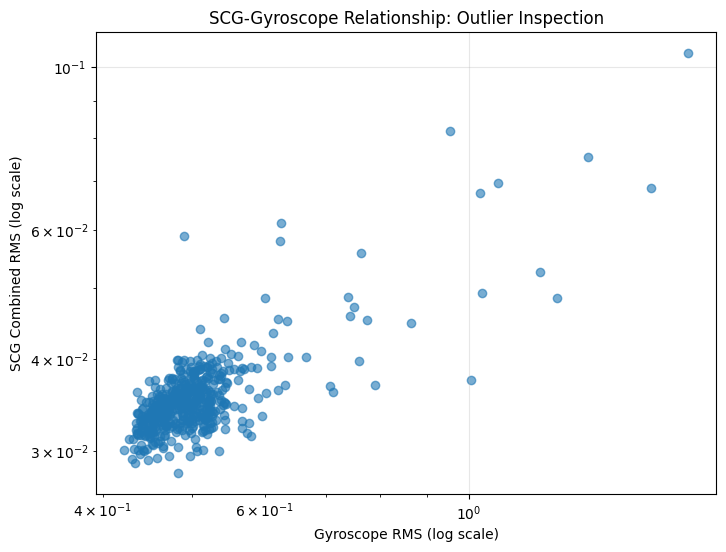

In [56]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

scg_rms = quality_df["Combined_RMS"].to_numpy()
gyro_rms = gyro_quality_df["Gyro_RMS"].to_numpy()

# Exclude increasingly large upper tails of gyroscope activity
percentiles = [100, 99, 95, 90]

print("===== OUTLIER SENSITIVITY ANALYSIS =====")

for percentile in percentiles:
    threshold = np.percentile(gyro_rms, percentile)
    mask = gyro_rms <= threshold

    p_r, p_p = pearsonr(scg_rms[mask], gyro_rms[mask])
    s_r, s_p = spearmanr(scg_rms[mask], gyro_rms[mask])

    print(f"\nKeeping lower {percentile}% of gyro activity")
    print("Cycles:", mask.sum())
    print(f"Pearson r:  {p_r:.4f} | p={p_p:.6g}")
    print(f"Spearman r: {s_r:.4f} | p={s_p:.6g}")

# Visualize the relationship on logarithmic axes
plt.figure(figsize=(8, 6))
plt.scatter(gyro_rms, scg_rms, alpha=0.6)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Gyroscope RMS (log scale)")
plt.ylabel("SCG Combined RMS (log scale)")
plt.title("SCG-Gyroscope Relationship: Outlier Inspection")
plt.grid(alpha=0.3)
plt.show()

In [57]:

import numpy as np
import pandas as pd

# Select representative cycles for initial annotation
selected_cycles = [
    10, 20, 21, 25, 30,
    40, 50, 75, 100, 120,
    150, 180, 220, 260, 300,
    331, 350, 400, 460, 500
]

annotation_df = pd.DataFrame({
    "Cycle": selected_cycles,
    "Bs_ms": np.nan,
    "Cs_ms": np.nan,
    "Es_ms": np.nan,
    "Gs_ms": np.nan,
    "Bd_ms": np.nan,
    "Fd_ms": np.nan,
    "Hd_ms": np.nan,
    "Annotation_Quality": "",
    "Notes": ""
})

annotation_df.to_csv(
    "CP01_manual_annotations.csv",
    index=False
)

print("===== INITIAL ANNOTATION TEMPLATE =====")
print(annotation_df.to_string(index=False))

from google.colab import files
files.download("CP01_manual_annotations.csv")


===== INITIAL ANNOTATION TEMPLATE =====
 Cycle  Bs_ms  Cs_ms  Es_ms  Gs_ms  Bd_ms  Fd_ms  Hd_ms Annotation_Quality Notes
    10    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
    20    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
    21    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
    25    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
    30    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
    40    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
    50    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
    75    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
   100    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
   120    NaN    NaN    NaN    NaN    NaN    NaN    NaN                         
   150    NaN    NaN    NaN    NaN    NaN    NaN    NaN              

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>